# Notebook 05 — Hard negative mining และการฝึกต่อเพื่อลด false positive บนฉากที่ไม่มีวัสดุ

**วัตถุประสงค์** ชุดพัฒนาแทบไม่มีภาพที่ไม่มีวัสดุ (หัวข้อ 4.1 ข้อ 6 ของ RESEARCH_PLAN) แบบจำลองจึงไม่เคยถูกสอนให้ตอบว่า "ไม่มีวัสดุ" ทั้งที่สถานะ none เป็นหนึ่งในสี่สถานะที่ระบบต้องตัดสินในการใช้งานจริง notebook นี้ศึกษาว่าการนำภาพที่ไม่มีวัสดุจาก Open Images V7 ซึ่งแบบจำลองทายผิด (hard negative) มาฝึกต่อแบบสองขั้น ลด false positive ได้เพียงใด และแลกกับความแม่นยำบนภาพที่มีวัสดุมากน้อยเพียงใด

**ขั้นตอน**

```
[Baseline]  model_v0 = แบบจำลองที่ฝึกด้วยชุด positive เดิมของแต่ละ arm (ไม่ฝึกใหม่)
     │
[Mine]      รัน model ปัจจุบันบน mining pool (OIv7, ไม่มีวัสดุ) ที่ conf ≥ 0.10
            → ภาพที่มี detection = hard negative (ภาพที่ทายผิด)
     │
[Stage 1]   freeze = 9 หรือ 11 | positive + hard negative | lr ปกติของ arm | 15 epochs
     │
[Stage 2]   freeze = 0 | ชุดผสมเดียวกัน | lr ต่ำลง 10 เท่า | 8 epochs
     │
[Re-mine]   ใช้แบบจำลองใหม่ mine รอบถัดไป → เพิ่ม hard negative → วนซ้ำ 3 รอบ
```

**Arm ที่เปรียบเทียบ (2 แบบจำลอง × 2 ระดับการ freeze = 4 run และ B ที่ imgsz 640 อีก 2 run)**

| Arm | model_v0 | ชุด positive | imgsz | preprocessing |
|---|---|---|---:|---|
| A | แบบจำลองที่ตรึงใน `configs/frozen_inference.yaml` (YOLO26s-seg + CBAM ที่ layer 16) | `data/preproc_P5_unsharp_A9_1450497fd9` (3,570 ภาพ) | 640 | P5_unsharp |
| B | `experiment/runs/bench_ws/yolo26s/weights/best.pt` (YOLO26s-seg) | `experiment/data/gold_ws_aug` (3,510 ภาพ) | 960 | ไม่มี |
| B640 | weights เดียวกับ B | เดียวกับ B | 640 | ไม่มี |

B640 เพิ่มเข้ามาหลังการรันครั้งแรกตามคำขอของผู้วิจัย เพื่อให้ arm A และ arm B เปรียบเทียบกันที่ขนาดภาพเดียวกัน (640) ผลของ arm B ที่ 960 ยังคงรายงานไว้ เพื่อแยกผลของขนาดภาพออกจากผลของ hard negative mining

แต่ละ arm ฝึกสองแบบ คือ `freeze=9` (ตรึง layer 0–8 ของ backbone ส่วนสกัด feature; SPPF และ C2PSA ยังฝึกได้) และ `freeze=11` (ตรึง backbone ทั้งหมด layer 0–10)

**กติกาของ notebook นี้**

1. การเลือกรอบและระดับการ freeze ใช้เฉพาะชุด val ของ positive และชุด neg-val เท่านั้น ตามกฎที่กำหนดล่วงหน้าในหัวข้อ 5
2. ชุด neg-test, dev test และ holdout ใช้รายงานผลเท่านั้น ชุด holdout ถูกเปิดผลแล้วใน Notebook 04 ผลบน holdout ในที่นี้จึงเป็นการวิเคราะห์หลังเปิดผล
3. Arm B ถูกฝึกบน `gold_ws_aug` ซึ่งมีภาพที่อยู่ในชุด test ของชุดพัฒนา (หัวข้อ 2.3) จึงไม่รายงานผลของ arm B บน dev test
4. ไม่มีสคริปต์แยก การดาวน์โหลด การ mine การฝึก และการประเมินทั้งหมดอยู่ใน notebook นี้ และทุกขั้นที่ใช้เวลานานมี cache จึงรันซ้ำได้โดยไม่คำนวณใหม่

## หลักฐานจากงานวิจัยที่รองรับการออกแบบ

| องค์ประกอบ | เหตุผล | อ้างอิง |
|---|---|---|
| Hard negative mining แบบวนรอบ (bootstrapping) | ภาพลบส่วนใหญ่ง่ายและไม่ให้ gradient ที่เป็นประโยชน์ การเลือกเฉพาะภาพที่แบบจำลองปัจจุบันทายผิดแล้วฝึกซ้ำเป็นวิธีมาตรฐานของ detector ตั้งแต่ยุค sliding window และยังใช้ใน detector แบบ CNN | Sung & Poggio (1998), *IEEE TPAMI* 20(1); Dalal & Triggs (2005), *CVPR*; Felzenszwalb et al. (2010), *IEEE TPAMI* 32(9); Shrivastava, Gupta & Girshick (2016), *CVPR* (OHEM) |
| ใช้ชุดข้อมูลภายนอกเป็นภาพลบ | การให้แบบจำลองเห็นข้อมูลนอกโดเมนระหว่างฝึก (outlier exposure) ทำให้แยกข้อมูลที่ไม่รู้จักได้ดีขึ้นและ generalize ไปยัง outlier ที่ไม่เคยเห็น detector ที่ประเมินแบบ closed-set ให้ false positive ความมั่นใจสูงบนวัตถุหรือฉากที่ไม่รู้จัก | Hendrycks, Mazeika & Dietterich (2019), *ICLR*; Dhamija et al. (2020), *WACV*; Kuznetsova et al. (2020), *IJCV* 128 (Open Images) |
| Stage 1 ตรึง backbone แล้ว Stage 2 ปลดทั้งหมดด้วย lr ต่ำ | การ fine-tune ทั้งเครือข่ายพร้อม head ที่ยังไม่ปรับตัวทำให้ feature ที่ฝึกไว้บิดเบือนและ generalize นอกโดเมนแย่ลง การฝึกส่วนบนก่อนแล้วค่อยปลดทั้งหมด (LP-FT, gradual unfreezing) ลดปัญหานี้ feature ชั้นล่างถ่ายโอนได้ดีกว่าชั้นบน | Kumar et al. (2022), *ICLR*; Howard & Ruder (2018), *ACL*; Yosinski et al. (2014), *NeurIPS* |
| คง positive เดิมไว้ในทุกขั้น | การฝึกต่อด้วยข้อมูลใหม่อย่างเดียวทำให้ลืมงานเดิม (catastrophic forgetting) การผสมข้อมูลเดิม (rehearsal) เป็นวิธีพื้นฐานในการป้องกัน | McCloskey & Cohen (1989); Kirkpatrick et al. (2017), *PNAS* 114(13) |
| จำกัดสัดส่วนภาพลบ | Ultralytics แนะนำให้มี background image ประมาณ 0–10% เพื่อลด FP โดยไม่ลด recall (COCO มี background ประมาณ 1%) งานนี้ใช้ภาพลบที่ "ยาก" จึงกำหนดเพดานสะสม 15% | Ultralytics, *Tips for Best Training Results* |

## 0. การตั้งค่า

In [1]:
import os
os.environ["YOLO_VERBOSE"] = "False"   # ปิด progress bar ของ ultralytics เพื่อให้ output ของ notebook กระชับ (บันทึก log ต่อ epoch เอง)
import sys, re, json, time, hashlib, platform, subprocess, random, math, shutil, gzip, warnings, contextlib, io, urllib.request
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import yaml as _yaml
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
warnings.filterwarnings("ignore", message="A single label was found")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "RESEARCH_PLAN.md").exists(), f"ROOT ไม่ถูกต้อง: {ROOT}"
EXP = ROOT.parent.parent / "experiment"
CLASS_NAMES = ["gravel", "sand"]
CLASS_COLORS = {"gravel": "#0072B2", "sand": "#E69F00", "mixed": "#999999", "none": "#DDDDDD"}
STATES = ["none", "gravel", "sand", "mixed"]

VERSIONS = json.loads((ROOT / "manifests" / "dataset_versions.json").read_text())
DEV = VERSIONS[-1]
DEV_DIR = ROOT / "data" / f"dev_{DEV['dev_hash']}"
MANIFEST = pd.read_csv(ROOT / DEV["manifest"])
SPLIT_META = json.loads((DEV_DIR / "split_meta.json").read_text())
EVAL_MIN_PX640 = 32 ** 2   # protocol "scope" เหมือน Notebook 03.5 และ 04

NOTEBOOK = "05_hard_negative_mining_retraining"
OUT_ROOT = ROOT / "outputs" / "05_hard_negative_mining"
FIG = OUT_ROOT / "figures"; TAB = OUT_ROOT / "tables"; RUNS = OUT_ROOT / "runs"; CACHE = OUT_ROOT / "cache"
for d in (FIG, TAB, RUNS, CACHE):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

def cfg_hash(d, n=10):
    return hashlib.sha256(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:n]

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def savefig(fig, path_no_ext):
    path_no_ext = Path(path_no_ext); path_no_ext.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"{path_no_ext}.{ext}", bbox_inches="tight")
    print(f"saved figure: {path_no_ext.relative_to(ROOT)}.png|pdf")

def save_table(df, path, index=False):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    print(f"saved table: {path.relative_to(ROOT)} ({len(df)} rows)")

def split_images(split):
    m = MANIFEST[MANIFEST.split == split].copy()
    m["path"] = [str(DEV_DIR / split / "images" / n) for n in m.silver_name]
    return m.reset_index(drop=True)

print("ROOT:", ROOT); print("DEV :", DEV_DIR.relative_to(ROOT)); print("splits:", SPLIT_META["counts"])

ROOT: /home/supawich/Desktop/Aggregate_Project/implement/research
DEV : data/dev_19659e679798
splits: {'train': 714, 'val': 131, 'test': 244}


In [2]:
def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

def environment_record():
    rec = dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%S%z"), python=sys.version.split()[0], platform=platform.platform(),
               cpu=platform.processor(), cpu_count=os.cpu_count(),
               packages={p: pkg_version(p) for p in ["torch", "torchvision", "ultralytics", "numpy", "opencv-python",
                                                     "albumentations", "pycocotools", "onnx", "onnxruntime", "openvino",
                                                     "tensorrt", "nncf", "ncnn", "sahi", "scikit-learn", "scikit-image", "thop",
                                                     "ultralytics-thop"]})
    try:
        import torch
        rec["cuda_available"] = torch.cuda.is_available()
        rec["torch_cuda"] = torch.version.cuda
        rec["cudnn"] = torch.backends.cudnn.version()
        if torch.cuda.is_available():
            p = torch.cuda.get_device_properties(0)
            rec["gpu"] = dict(name=p.name, total_memory_gb=round(p.total_memory / 2**30, 2), capability=f"{p.major}.{p.minor}")
    except Exception as e:
        rec["torch_error"] = str(e)
    try:
        rec["nvidia_smi"] = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                                                     "--format=csv,noheader"], text=True).strip()
    except Exception:
        rec["nvidia_smi"] = None
    try:
        rec["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        rec["git_commit"] = None
    return rec

ENV = environment_record()
(OUT_ROOT / "env_manifest.json").write_text(json.dumps(ENV, indent=2))
print(json.dumps(ENV, indent=2))

{
  "timestamp": "2026-10-20T21:19:13+0700",
  "python": "3.12.3",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "cpu": "x86_64",
  "cpu_count": 20,
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "ultralytics": "8.4.180",
    "numpy": "2.5.4",
    "opencv-python": "5.0.0.93",
    "albumentations": "2.0.8",
    "pycocotools": "2.0.11",
    "onnx": "1.23.2",
    "onnxruntime": "1.31.0",
    "openvino": "2026.4.1",
    "tensorrt": null,
    "nncf": null,
    "ncnn": null,
    "sahi": "0.12.8",
    "scikit-learn": "1.9.1",
    "scikit-image": "0.26.0",
    "thop": null,
    "ultralytics-thop": "2.2.2"
  },
  "cuda_available": true,
  "torch_cuda": "13.0",
  "cudnn": 92400,
  "gpu": {
    "name": "NVIDIA GeForce RTX 3080 Ti",
    "total_memory_gb": 11.62,
    "capability": "8.6"
  },
  "nvidia_smi": "NVIDIA GeForce RTX 3080 Ti, 580.178.04, 12288 MiB",
  "git_commit": "3a70169003cd2129868b88aa091d92451c2c6862"
}


### 0.1 ฟังก์ชันการประเมินและโมดูล attention

สองเซลล์ต่อไปนี้คัดลอกจาก Notebook 04 โดยไม่แก้ไข (สร้าง notebook นี้ด้วยการอ่าน source ของ Notebook 04 โดยตรง) เพื่อให้ metric ระดับ instance, ระดับสถานะ, cluster bootstrap และการโหลด checkpoint ที่มี CBAM เหมือนกับที่ใช้ในการตรึงแบบจำลองทุกประการ

In [3]:
# ---------- การประเมินแบบ COCO (pycocotools) พร้อม ignore region และ metric ระดับสถานะ ----------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util
from ultralytics import YOLO

def load_gt(json_path, protocol="scope"):
    # protocol: "scope" = ignore region ของ Silver และ GT ที่เล็กกว่า EVAL_MIN_PX640 (protocol หลัก); "ignore" = เฉพาะ ignore region ของ Silver;
    # "strict" = นับทุกชิ้นเป็น GT ปกติ
    d = json.loads(Path(json_path).read_text())
    side = {im["id"]: max(im["width"], im["height"]) for im in d["images"]}
    for a in d["annotations"]:
        if protocol == "strict":
            a["iscrowd"] = 0
        elif protocol == "scope" and a["area"] * (640 / side[a["image_id"]]) ** 2 < EVAL_MIN_PX640:
            a["iscrowd"] = 1
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt

def predict_dets(weights, records, imgsz=640, conf=0.001, max_det=100, batch=8, transform=None, half=False, desc=""):
    """records: DataFrame with image_id, path, width, height. transform: callable(BGR)->BGR applied before inference."""
    model = YOLO(str(weights))
    dets, t0 = [], time.time()
    recs = records.to_dict("records")
    for k in range(0, len(recs), batch):
        chunk = recs[k:k + batch]
        imgs = [cv2.imread(r["path"]) for r in chunk]
        if transform is not None:
            imgs = [transform(im) for im in imgs]
        res = model.predict(imgs, imgsz=imgsz, conf=conf, max_det=max_det, retina_masks=True, quantize=16 if half else None, verbose=False)
        for r, out in zip(chunk, res):
            if out.masks is None or len(out.boxes) == 0:
                continue
            ms = out.masks.data.cpu().numpy().astype(np.uint8)
            xyxy = out.boxes.xyxy.cpu().numpy(); cls = out.boxes.cls.cpu().numpy().astype(int); sc = out.boxes.conf.cpu().numpy()
            for m, b, c, s in zip(ms, xyxy, cls, sc):
                if m.shape != (r["height"], r["width"]):
                    m = cv2.resize(m, (r["width"], r["height"]), interpolation=cv2.INTER_NEAREST)
                rle = mask_util.encode(np.asfortranarray(m)); rle["counts"] = rle["counts"].decode()
                dets.append(dict(image_id=int(r["image_id"]), category_id=int(c) + 1, score=float(s),
                                 segmentation=rle, bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
                                 area=float(m.sum())))
    print(f"predicted {len(recs)} images -> {len(dets)} detections in {time.time()-t0:.1f}s {desc}")
    return dets

def cached_dets(cache_file, fn):
    cache_file = Path(cache_file)
    if cache_file.exists():
        with gzip.open(cache_file, "rt") as f:
            return json.load(f)
    dets = fn()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache_file, "wt") as f:
        json.dump(dets, f)
    return dets

def run_cocoeval(gt, dets, iou_type="segm", img_ids=None):
    dts = [dict(d) for d in dets if img_ids is None or d["image_id"] in set(img_ids)]
    if iou_type == "bbox":
        for d in dts:
            d.pop("segmentation", None)
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dts) if dts else COCO()
        E = COCOeval(gt, dt, iou_type)
        if img_ids is not None:
            E.params.imgIds = sorted(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    return E

STAT_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def per_class_ap(E):
    out = {}
    p = E.eval["precision"]  # [T, R, K, A, M]
    for k, cid in enumerate(E.params.catIds):
        pr = p[:, :, k, 0, -1]
        out[CLASS_NAMES[cid - 1]] = dict(AP=float(np.mean(pr[pr > -1])) if (pr > -1).any() else float("nan"),
                                         AP50=float(np.mean(p[0, :, k, 0, -1][p[0, :, k, 0, -1] > -1])) if (p[0, :, k, 0, -1] > -1).any() else float("nan"))
    return out

def image_records(E):
    # ข้อมูลการจับคู่ราย (ภาพ, คลาส) ที่ areaRng='all', maxDet=100 ใช้คำนวณ AP ซ้ำแบบ bootstrap และรายกลุ่ม
    recs = {}
    a_all, md = E.params.areaRng[0], E.params.maxDets[-1]
    for e in E.evalImgs:
        if e is None or e["aRng"] != a_all or e["maxDet"] != md:
            continue
        recs[(e["image_id"], e["category_id"])] = dict(
            scores=np.asarray(e["dtScores"], float), matched=np.asarray(e["dtMatches"]) > 0,
            dt_ig=np.asarray(e["dtIgnore"]).astype(bool), npig=int((np.asarray(e["gtIgnore"]) == 0).sum()))
    return recs

def ap_from_records(recs, img_ids, cat_id, n_iou=10):
    # COCO 101-point interpolated AP จากข้อมูลการจับคู่ (เหมือน COCOeval.accumulate)
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    if not rs:
        return float("nan")
    npig = sum(r["npig"] for r in rs)
    if npig == 0:
        return float("nan")
    scores = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-scores, kind="mergesort")
    M = np.concatenate([r["matched"] for r in rs], axis=1)[:, order]
    IG = np.concatenate([r["dt_ig"] for r in rs], axis=1)[:, order]
    rec_thr = np.linspace(0, 1, 101); aps = []
    for t in range(n_iou):
        tp = np.cumsum(M[t] & ~IG[t]); fp = np.cumsum(~M[t] & ~IG[t])
        rc = tp / npig; pr = tp / np.maximum(tp + fp, np.spacing(1))
        pr = np.maximum.accumulate(pr[::-1])[::-1]
        idx = np.searchsorted(rc, rec_thr, side="left")
        q = np.where(idx < len(pr), pr[np.minimum(idx, len(pr) - 1)], 0.0)
        aps.append(q.mean())
    return float(np.mean(aps))

def operating_point(recs, img_ids, cat_id, iou_index=0, thresholds=None):
    # P/R/F1 ที่ IoU 0.5 สำหรับแต่ละ confidence threshold
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    npig = sum(r["npig"] for r in rs)
    s = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    m = np.concatenate([r["matched"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    ig = np.concatenate([r["dt_ig"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2) if thresholds is None else np.atleast_1d(thresholds)
    rows = []
    for th in thresholds:
        k = (s >= th) & ~ig
        tp = int((m & k).sum()); fp = int((~m & k).sum()); fn = npig - tp
        p = tp / max(tp + fp, 1); r_ = tp / max(npig, 1); f1 = 2 * p * r_ / max(p + r_, 1e-9)
        rows.append(dict(conf=float(th), TP=tp, FP=fp, FN=fn, precision=p, recall=r_, F1=f1))
    return pd.DataFrame(rows)

def l1_evaluate(gt_json, dets, records, protocol="scope"):
    """Instance-level evaluation: mask and box COCO stats, per-class AP, matching records."""
    gt = load_gt(gt_json, protocol)
    ids = records.image_id.astype(int).tolist()
    out = {}
    for it in ("segm", "bbox"):
        E = run_cocoeval(gt, dets, it, ids)
        out[it] = dict(stats=dict(zip(STAT_NAMES, map(float, E.stats))), per_class=per_class_ap(E), recs=image_records(E))
    # ตรวจว่า AP ที่คำนวณซ้ำตรงกับ COCOeval (ยืนยันความถูกต้องของ ap_from_records)
    for c in (1, 2):
        a1 = ap_from_records(out["segm"]["recs"], ids, c)
        a0 = out["segm"]["per_class"][CLASS_NAMES[c - 1]]["AP"]
        if not (np.isnan(a0) and np.isnan(a1)):
            assert abs(a0 - a1) < 2e-3, f"AP recomputation mismatch for class {c}: {a0} vs {a1}"
    return out

def summarize_l1(res, prefix=""):
    s = {}
    for it, tag in (("segm", "mask"), ("bbox", "box")):
        st = res[it]["stats"]
        s.update({f"{prefix}{tag}_AP": st["AP"], f"{prefix}{tag}_AP50": st["AP50"], f"{prefix}{tag}_AP75": st["AP75"],
                  f"{prefix}{tag}_APs": st["AP_small"], f"{prefix}{tag}_APm": st["AP_medium"], f"{prefix}{tag}_APl": st["AP_large"]})
        for c, v in res[it]["per_class"].items():
            s[f"{prefix}{tag}_AP_{c}"] = v["AP"]
    return s

# ---------- ระดับสถานะ (L2) ----------
STATE_MIN_CONF = 0.05   # ใช้ detection ที่ conf >= ค่านี้ในการคำนวณคะแนนสถานะ (กำหนดล่วงหน้า)

def state_scores(dets, records):
    # S_c = sum(conf * mask_area / image_area) ต่อภาพต่อคลาส
    area = dict(zip(records.image_id.astype(int), records.width * records.height))
    S = defaultdict(lambda: np.zeros(2))
    for d in dets:
        if d["score"] >= STATE_MIN_CONF and d["image_id"] in area:
            S[d["image_id"]][d["category_id"] - 1] += d["score"] * d["area"] / area[d["image_id"]]
    return pd.DataFrame([dict(image_id=i, S_gravel=S[i][0], S_sand=S[i][1]) for i in records.image_id.astype(int)])

def states_from_presence(g, s):
    return np.where(g & s, "mixed", np.where(g, "gravel", np.where(s, "sand", "none")))

def fit_state_thresholds(scores, records):
    # เลือก theta_c บน val เพื่อให้ F1 ของการปรากฏของคลาสสูงสุด
    df = scores.merge(records[["image_id", "state"]], on="image_id")
    out = {}
    for c in CLASS_NAMES:
        y = df.state.isin([c, "mixed"]).values; x = df[f"S_{c}"].values
        cands = np.unique(np.concatenate([[1e-6], np.quantile(x, np.linspace(0, 1, 201))]))
        f1 = []
        for th in cands:
            p = x >= th; tp = (p & y).sum(); fp = (p & ~y).sum(); fn = (~p & y).sum()
            f1.append(2 * tp / max(2 * tp + fp + fn, 1))
        out[c] = float(cands[int(np.argmax(f1))])
    return out

def l2_evaluate(scores, records, thresholds):
    from sklearn.metrics import balanced_accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, average_precision_score
    df = scores.merge(records[["image_id", "state", "group_merged"]], on="image_id")
    pred = states_from_presence(df.S_gravel.values >= thresholds["gravel"], df.S_sand.values >= thresholds["sand"])
    y = df.state.values
    labels = [s for s in STATES if s in set(y) | set(pred)]
    res = dict(n=len(df), balanced_accuracy=float(balanced_accuracy_score(y, pred)),
               macro_f1=float(f1_score(y, pred, average="macro", labels=labels, zero_division=0)),
               kappa=float(cohen_kappa_score(y, pred)), accuracy=float((y == pred).mean()),
               labels=labels, confusion=confusion_matrix(y, pred, labels=labels).tolist())
    for c in CLASS_NAMES:
        yc = df.state.isin([c, "mixed"]).values
        res[f"presence_AP_{c}"] = float(average_precision_score(yc, df[f"S_{c}"])) if yc.any() and (~yc).any() else float("nan")
    df["pred_state"] = pred
    return res, df

# ---------- ช่วงความเชื่อมั่นแบบ cluster bootstrap ----------
def cluster_bootstrap(records, stat_fn, n_boot=1000, seed=SEED, group_col="group_merged"):
    rng = np.random.default_rng(seed)
    groups = records[group_col].unique()
    by_g = {g: records.image_id[records[group_col] == g].astype(int).tolist() for g in groups}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(groups, size=len(groups), replace=True)
        ids = [i for g in pick for i in by_g[g]]
        vals.append(stat_fn(ids))
    vals = np.asarray(vals, float)
    return dict(mean=float(np.nanmean(vals)), ci_low=float(np.nanpercentile(vals, 2.5)), ci_high=float(np.nanpercentile(vals, 97.5)),
                n_boot=n_boot, n_clusters=len(groups))

def bootstrap_mask_ap(res, records, n_boot=1000):
    recs = res["segm"]["recs"]
    def stat(ids):
        return np.nanmean([ap_from_records(recs, ids, c) for c in (1, 2)])
    return cluster_bootstrap(records, stat, n_boot)

In [4]:
# ---------- โมดูล attention และการแทรกเข้า YOLO26 (ต้องนิยามก่อนโหลด checkpoint ที่มี attention) ----------
import torch
import torch.nn as nn
from ultralytics.nn.modules.block import C3k2
from ultralytics.nn.modules.conv import SpatialAttention

ATT_RECORD = {"on": False}   # เก็บค่า attention ล่าสุดเฉพาะตอนทำ visualization (ไม่ให้กระทบการวัด latency)

class ECA(nn.Module):
    """Efficient Channel Attention (Wang et al., CVPR 2020): GAP -> 1D conv (adaptive k) -> sigmoid.
    ปรับให้เริ่มต้นเป็น identity: w = 2*sigmoid(z) และ conv เริ่มที่ศูนย์ (w = 1 ตอนเริ่ม)"""
    def __init__(self, c, gamma=2, b=1):
        super().__init__()
        k = int(abs((math.log2(c) + b) / gamma)); k = k if k % 2 else k + 1
        self.k = k
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.conv.weight)
        self.last_weights = None
    def forward(self, x):
        y = self.pool(x).squeeze(-1).transpose(-1, -2)            # (B, 1, C)
        w = 2 * torch.sigmoid(self.conv(y)).transpose(-1, -2).unsqueeze(-1)  # (B, C, 1, 1)
        if not self.training and ATT_RECORD["on"]:
            self.last_weights = w.detach().float().cpu()
        return x * w

class CBAMPaper(nn.Module):
    """CBAM ตาม Woo et al. (ECCV 2018): channel attention จาก avg-pool และ max-pool ผ่าน MLP ร่วม (reduction r)
    ตามด้วย spatial attention (conv 7x7 บน [mean, max] ตามแกน channel) ปรับให้เริ่มต้นเป็น identity ด้วย 2*sigmoid และ
    น้ำหนักชั้นสุดท้ายเป็นศูนย์"""
    def __init__(self, c, r=16, k=7):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(h, c, 1, bias=False))
        nn.init.zeros_(self.mlp[2].weight)
        self.spatial = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.spatial.weight)
        self.last_channel = None; self.last_spatial = None
    def forward(self, x):
        ca = 2 * torch.sigmoid(self.mlp(torch.amax(x, (2, 3), keepdim=True)) + self.mlp(torch.mean(x, (2, 3), keepdim=True)))
        x = x * ca
        sa = 2 * torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        if not self.training and ATT_RECORD["on"]:
            self.last_channel = ca.detach().float().cpu(); self.last_spatial = sa.detach().float().cpu()
        return x * sa

class C3k2Att(C3k2):
    """C3k2 ที่ต่อ attention ไว้ที่ output; ชื่อพารามิเตอร์เดิมของ C3k2 ไม่เปลี่ยน จึงโอน pretrained weights ได้ครบ"""
    def forward(self, x):
        return self.att(super().forward(x))

def insert_attention(seg_model, kind, layers):
    net = seg_model.model
    for i in layers:
        m = net[i]
        assert isinstance(m, C3k2), f"layer {i} is {type(m).__name__}, expected C3k2"
        c = m.cv2.conv.out_channels
        m.__class__ = C3k2Att
        m.att = ECA(c) if kind == "eca" else CBAMPaper(c)
    return seg_model

ATT_SPEC = dict(kind=None, layers=[])
TRANSFER_LOG = []

from ultralytics.models.yolo.segment import SegmentationTrainer
class AttSegTrainer(SegmentationTrainer):
    """สร้างแบบจำลองจาก yaml, แทรก attention ก่อน แล้วจึงโหลด weights (รวมกรณี resume ที่ weights มี attention แล้ว)"""
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg=cfg, weights=None, verbose=False)
        insert_attention(model, ATT_SPEC["kind"], ATT_SPEC["layers"])
        if weights is not None:
            src = (weights.get("ema") or weights["model"]) if isinstance(weights, dict) else weights
            src_sd = src.float().state_dict(); dst_sd = model.state_dict()
            matched = [k for k, v in dst_sd.items() if k in src_sd and src_sd[k].shape == v.shape]
            n_par = sum(dst_sd[k].numel() for k in matched); tot = sum(v.numel() for v in dst_sd.values())
            TRANSFER_LOG.append(dict(kind=ATT_SPEC["kind"], layers=list(ATT_SPEC["layers"]), tensors_matched=len(matched),
                                     tensors_total=len(dst_sd), params_matched=n_par, params_total=tot))
            model.load(weights)
        return model

## 1. ชุดภาพลบจาก Open Images V7

**Method** ใช้ image-level label ที่มนุษย์ยืนยัน (`oidv7-*-annotations-human-imagelabels.csv`) ของ split validation และ test ตัดภาพที่มี label บวก (Confidence = 1) ของคลาสที่อาจเป็นวัสดุเป้าหมายหรือคล้ายมาก ออกทั้งหมด ได้แก่ Sand, Rock, Gravel, Soil, Stone, Pebble, Rubble, Boulder, Bedrock, Beach, Desert, Quarry, Sandstone, Mud และ Cobblestone จากนั้นแบ่งภาพที่เหลือเป็นสองชนิด

- **context** ภาพที่มี label ของฉากคล้ายจุดเทวัสดุ ได้แก่ Asphalt, Road, Road surface, Concrete, Cement, Wall, Floor, Ground, Land lot, Parking, Construction, Construction equipment, Truck และ Brick ซึ่งเป็นฉากที่แบบจำลองมีแนวโน้มสับสนกับวัสดุมากที่สุด
- **other** ภาพทั่วไปที่สุ่มจากส่วนที่เหลือ เพื่อครอบคลุมสิ่งที่กล้องอาจเห็นได้ เช่น คน ยานพาหนะ หรือท้องฟ้า

| ชุด | split ของ OIv7 | context | other | หน้าที่ |
|---|---|---:|---:|---|
| mining pool | validation | ส่วนที่เหลือ (~2,100) | 1,900 | ใช้ mine hard negative ทุกรอบ |
| neg-val | validation | 500 | 500 | ใช้เลือกรอบและระดับการ freeze ไม่ถูก mine |
| neg-test | test | 750 | 750 | รายงานผลครั้งสุดท้าย คนละ split กับข้างบน |

**Rationale** การแยก neg-val ออกจาก mining pool ทำให้วัด FP บนภาพที่ไม่เคยเข้าสู่การฝึกได้ ส่วน neg-test มาจากคนละ split ของ OIv7 จึงไม่ซ้อนทับกับสองชุดแรก การมีทั้ง context และ other ทำให้แยกได้ว่าการลด FP เกิดกับฉากที่คล้ายหน้างานหรือกับภาพทั่วไป

**Reference** Kuznetsova et al. (2020), *IJCV* 128: 1956–1981; Benenson & Ferrari (2022), arXiv:2211.11861 (Open Images V7)

**Implementation** ดาวน์โหลดภาพจาก bucket สาธารณะ `open-images-dataset` (ภาพย่อด้านยาว 1024 px ที่ Google เผยแพร่) ตรวจว่าเปิดภาพได้ บันทึก SHA-256 และ label ที่ยืนยันของแต่ละภาพไว้ใน manifest

**Limitation** label ระดับภาพของ OIv7 ยืนยันเฉพาะคลาสที่ถูกเสนอให้ตรวจ การไม่มี label "Gravel" จึงไม่ได้รับประกันว่าภาพไม่มีกรวด ภาพที่ mine ได้จึงต้องตรวจด้วยตาจาก contact sheet ในหัวข้อ 3 และภาพที่ตรวจแล้วว่ามีวัสดุจริงต้องตัดออกในรอบถัดไป

In [5]:
OI_META = ROOT / "data" / "oiv7_meta"; OI_META.mkdir(parents=True, exist_ok=True)
OI_URLS = {"oidv7-class-descriptions.csv": "https://storage.googleapis.com/openimages/v7/oidv7-class-descriptions.csv",
           "oidv7-val-annotations-human-imagelabels.csv": "https://storage.googleapis.com/openimages/v7/oidv7-val-annotations-human-imagelabels.csv",
           "oidv7-test-annotations-human-imagelabels.csv": "https://storage.googleapis.com/openimages/v7/oidv7-test-annotations-human-imagelabels.csv"}
for fn, url in OI_URLS.items():
    dst = OI_META / fn
    if not dst.exists():
        tmp = dst.with_suffix(".part"); urllib.request.urlretrieve(url, tmp); tmp.rename(dst)
meta_rec = {fn: dict(url=u, sha256=sha256_file(OI_META / fn), bytes=(OI_META / fn).stat().st_size) for fn, u in OI_URLS.items()}
(OI_META / "SOURCES.json").write_text(json.dumps(meta_rec, indent=2))
display(pd.DataFrame(meta_rec).T)

OI_CLS = pd.read_csv(OI_META / "oidv7-class-descriptions.csv")
ID2NAME = dict(zip(OI_CLS.LabelName, OI_CLS.DisplayName))
EXCLUDE = ["Sand", "Rock", "Gravel", "Soil", "Stone", "Pebble", "Rubble", "Boulder", "Bedrock", "Beach", "Desert", "Quarry",
           "Sandstone", "Mud", "Cobblestone"]
CONTEXT = ["Asphalt", "Road", "Road surface", "Concrete", "Cement", "Wall", "Floor", "Ground", "Land lot", "Parking",
           "Construction", "Construction equipment", "Truck", "Brick"]
EX_IDS = set(OI_CLS.LabelName[OI_CLS.DisplayName.isin(EXCLUDE)]); CTX_IDS = set(OI_CLS.LabelName[OI_CLS.DisplayName.isin(CONTEXT)])
assert len(EX_IDS) >= len(EXCLUDE) and len(CTX_IDS) >= len(CONTEXT), "class names not found in OIv7 descriptions"

def oi_candidates(csv):
    L = pd.read_csv(csv, usecols=["ImageID", "LabelName", "Confidence"])
    pos = L[L.Confidence == 1]
    bad = set(pos.ImageID[pos.LabelName.isin(EX_IDS)])
    ctx = sorted(set(pos.ImageID[pos.LabelName.isin(CTX_IDS)]) - bad)
    other = sorted(set(L.ImageID) - bad - set(ctx))
    ctx_labels = pos[pos.ImageID.isin(set(ctx)) & pos.LabelName.isin(CTX_IDS)].groupby("ImageID").LabelName.apply(
        lambda s: "|".join(sorted({ID2NAME[x] for x in s})))
    return dict(n_all=L.ImageID.nunique(), n_excluded=len(bad), ctx=ctx, other=other, ctx_labels=ctx_labels)

CAND = {"validation": oi_candidates(OI_META / "oidv7-val-annotations-human-imagelabels.csv"),
        "test": oi_candidates(OI_META / "oidv7-test-annotations-human-imagelabels.csv")}
display(pd.DataFrame({s: dict(images=c["n_all"], excluded_material=c["n_excluded"], context=len(c["ctx"]), other=len(c["other"]))
                      for s, c in CAND.items()}).T)

,url,sha256,bytes
oidv7-class-descriptions.csv,https://storage.googleapis.com/openimages/v7/o...,84a4373a0efb7fd6d93fe19b0e7ceb6c1b855c233d13b9...,501178
oidv7-val-annotations-human-imagelabels.csv,https://storage.googleapis.com/openimages/v7/o...,92ddbdfceb3626e044df5e89100b24f6c22a79c1888a4b...,28392297
oidv7-test-annotations-human-imagelabels.csv,https://storage.googleapis.com/openimages/v7/o...,917d3ca8c0a2e09d652fb3148e9264df6117bfcaccf425...,93606939


,images,excluded_material,context,other
validation,41620,1155,2611,37854
test,125436,5986,18740,100710


In [6]:
# การสุ่มเลือกภาพของแต่ละชุด (seed คงที่) — neg-val แยกจาก mining pool ก่อน แล้วจึงกำหนด pool จากส่วนที่เหลือ
rng = np.random.default_rng(SEED)
def pick(ids, n):
    ids = np.array(ids); return list(rng.permutation(ids)[:n]) if n < len(ids) else list(rng.permutation(ids))
v_ctx = list(rng.permutation(CAND["validation"]["ctx"])); v_oth = list(rng.permutation(CAND["validation"]["other"]))
N_POOL_OTHER = 1900
SUBSETS = {"negval": [("validation", i, "context") for i in v_ctx[:500]] + [("validation", i, "other") for i in v_oth[:500]],
           "pool": [("validation", i, "context") for i in v_ctx[500:]] + [("validation", i, "other") for i in v_oth[500:500 + N_POOL_OTHER]],
           "negtest": [("test", i, "context") for i in pick(CAND["test"]["ctx"], 750)] + [("test", i, "other") for i in pick(CAND["test"]["other"], 750)]}
assert not ({x[1] for x in SUBSETS["negval"]} & {x[1] for x in SUBSETS["pool"]})

NEG_ROOT = ROOT / "data" / "oiv7_neg"
def download_one(split, iid, dst):
    if dst.exists():
        return True
    url = f"https://s3.amazonaws.com/open-images-dataset/{split}/{iid}.jpg"
    for attempt in range(3):
        try:
            data = urllib.request.urlopen(url, timeout=30).read()
            if cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR) is None:
                return False
            tmp = dst.with_suffix(".part"); tmp.write_bytes(data); tmp.rename(dst)
            return True
        except Exception:
            time.sleep(1 + 2 * attempt)
    return False

NEG_CSV = NEG_ROOT / "manifest.csv"
if NEG_CSV.exists():
    NEG = pd.read_csv(NEG_CSV)
else:
    rows, t0 = [], time.time()
    for sub, items in SUBSETS.items():
        d = NEG_ROOT / sub / "images"; d.mkdir(parents=True, exist_ok=True)
        with ThreadPoolExecutor(16) as ex:
            ok = list(ex.map(lambda x: download_one(x[0], x[1], d / f"{x[1]}.jpg"), items))
        for (split, iid, kind), good in zip(items, ok):
            if good:
                p = d / f"{iid}.jpg"; h, w = cv2.imread(str(p)).shape[:2]
                rows.append(dict(subset=sub, oi_split=split, oi_id=iid, kind=kind, path=str(p), width=w, height=h,
                                 sha256=sha256_file(p), context_labels=CAND[split]["ctx_labels"].get(iid, "")))
        print(f"{sub}: {sum(ok)}/{len(items)} downloaded ({time.time()-t0:.0f}s)")
    NEG = pd.DataFrame(rows); NEG.insert(0, "image_id", np.arange(len(NEG)) + 200000)
    NEG.to_csv(NEG_CSV, index=False)
assert NEG.sha256.is_unique, "duplicate image across subsets"
NEG["context_labels"] = NEG.context_labels.fillna(""); NEG["group_merged"] = NEG.oi_id; NEG["state"] = "none"
display(pd.crosstab(NEG.subset, NEG.kind, margins=True))

kind,context,other,All
subset,,,
negtest,750,750,1500
negval,500,500,1000
pool,2111,1900,4011
All,3361,3150,6511


saved figure: outputs/05_hard_negative_mining/figures/fig01_oiv7_negative_examples.png|pdf


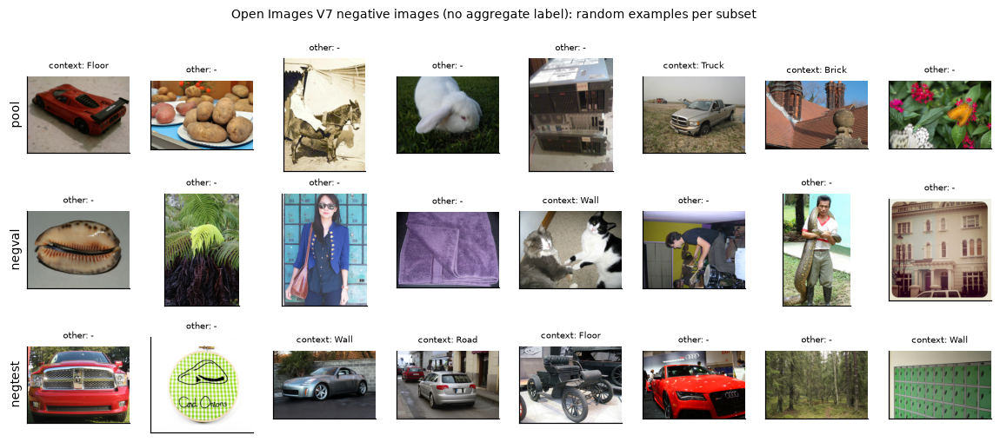

In [7]:
fig, axes = plt.subplots(3, 8, figsize=(13, 5.2))
for r, sub in enumerate(["pool", "negval", "negtest"]):
    g = NEG[NEG.subset == sub].sample(8, random_state=SEED)
    for c, x in enumerate(g.itertuples()):
        ax = axes[r, c]; im = cv2.imread(x.path)[..., ::-1]
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{x.kind}: {(x.context_labels or '-').split('|')[0]}", fontsize=6.5)
        if c == 0:
            ax.set_ylabel(sub, fontsize=9)
fig.suptitle("Open Images V7 negative images (no aggregate label): random examples per subset", fontsize=9)
savefig(fig, FIG / "fig01_oiv7_negative_examples"); plt.show()

## 2. Arm และ model_v0

### 2.1 นิยามของ arm

**Method** model_v0 ของแต่ละ arm คือแบบจำลองที่ฝึกไว้แล้วด้วยชุด positive ของ arm นั้น ไม่ฝึกใหม่ การฝึกต่อทุกขั้นใช้ optimizer, augmentation, imgsz และ preprocessing ตามสูตรเดิมของ arm เปลี่ยนเฉพาะสิ่งที่การทดลองกำหนด (ภาพลบ, freeze, lr และจำนวน epoch)

| พารามิเตอร์ | Arm A | Arm B | ที่มา |
|---|---|---|---|
| optimizer, lr ปกติ | AdamW, 0.001 | AdamW, 0.001667 | A: `model_card.json`; B: ค่าที่ `optimizer=auto` เลือก ตรวจย้อนจาก lr ใน `results.csv` |
| batch | 16 | 8 | A: เท่าเดิม; B: ลดลงเพื่อให้พอกับหน่วยความจำ GPU ที่ 960 px (`nbs=64` ทำให้การสะสม gradient ชดเชย) |
| online augmentation | ตาม `model_card.json` (mosaic 1.0, copy-paste 0.3 ฯลฯ) | ตาม `args.yaml` เดิม (ปิด geometric/HSV, erasing 0.4) | สูตรเดิม |
| Stage 1 | 15 epochs, freeze ∈ {9, 11}, lr0 ปกติ, warmup 1 epoch, lrf 0.1 | เหมือนกัน | — |
| Stage 2 | 8 epochs, freeze 0, lr0 = ปกติ / 10, ไม่มี warmup, lrf 0.1 | เหมือนกัน | — |

**Rationale** ช่วง lr ต่ำลง 5–10 เท่าใน Stage 2 เป็นแนวทางของ discriminative fine-tuning และ LP-FT ที่ปรับ feature ทั้งหมดโดยไม่ลบล้างสิ่งที่เรียนไว้ (Howard & Ruder, 2018; Kumar et al., 2022) ตั้ง `warmup_bias_lr = 0` เพราะค่าเริ่มต้น 0.1 ออกแบบไว้สำหรับการฝึกจากศูนย์ด้วย SGD และจะทำลาย bias ของแบบจำลองที่ฝึกแล้ว ใช้ `last.pt` ของแต่ละขั้นเป็นผลลัพธ์ (ไม่ใช้ `best.pt`) เพราะ fitness ของ Ultralytics วัดบน val ที่ไม่มีภาพลบ จึงไม่สะท้อนผลของ hard negative การเลือกจริงทำในหัวข้อ 5

**Limitation** Arm B ฝึกด้วย batch ต่างจากเดิม (เดิมใช้ autobatch) และ ultralytics ต่างเวอร์ชัน ผลของ arm B เทียบระหว่างรอบภายใน arm ได้ แต่เทียบกับ arm A ได้เชิงแนวโน้มเท่านั้น

In [8]:
FROZEN = _yaml.safe_load((ROOT / "configs" / "frozen_inference.yaml").read_text())
CARD = json.loads((ROOT / "outputs" / "03.5_best_model_evaluation" / "model_card.json").read_text())
WA = ROOT / FROZEN["weights"]; assert sha256_file(WA) == FROZEN["weights_sha256"], "frozen checkpoint changed"
WB = EXP / "runs" / "bench_ws" / "yolo26s" / "weights" / "best.pt"
B_ARGS = _yaml.safe_load((WB.parent.parent / "args.yaml").read_text())

def _unsharp(img, sigma=1.0, amount=0.5):   # P5_unsharp ตามที่ตรึงไว้ (เหมือน Notebook 04)
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)
assert FROZEN["preprocessing"] == "P5_unsharp"

AUG_KEYS = ["hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale", "shear", "perspective", "flipud", "fliplr",
            "mosaic", "mixup", "copy_paste", "copy_paste_mode"]
ARMS = {
    "A": dict(label="A: research best (YOLO26s-seg + CBAM@16)", v0=WA, imgsz=640, pp=_unsharp,
              pos_root=ROOT / "data" / "preproc_P5_unsharp_A9_1450497fd9", train_sub="train", val_sub="val",
              trainer=AttSegTrainer, att=dict(kind="cbam", layers=[16]), batch=16, lr0=0.001, momentum=0.937,
              aug={k: CARD["online_augmentation"][k] for k in AUG_KEYS}),
    "B": dict(label="B: bench_ws YOLO26s-seg (960)", v0=WB, imgsz=960, pp=None,
              pos_root=EXP / "data" / "gold_ws_aug", train_sub="train", val_sub="valid",
              trainer=None, att=None, batch=8, lr0=0.001667, momentum=0.9,
              aug={**{k: B_ARGS[k] for k in AUG_KEYS}, "erasing": B_ARGS["erasing"], "auto_augment": B_ARGS["auto_augment"]}),
}
# B640: weights v0 เดียวกับ arm B แต่ inference และการฝึกต่อทุกขั้นที่ imgsz 640 เท่ากับ arm A (ควบคุมตัวแปรขนาดภาพ)
ARMS["B640"] = {**ARMS["B"], "label": "B640: bench_ws YOLO26s-seg (640)", "imgsz": 640, "batch": 16}
FREEZES = [9, 11]
N_ROUNDS = 3
MINE_CONF = 0.10          # detection ที่ conf ≥ ค่านี้บนภาพลบ = ทายผิด (ช่วง 0.1–0.25 ตามแผน; ใช้ขอบล่างเพื่อเก็บ near-miss)
ADD_FRAC = 0.05           # เพิ่ม hard negative ต่อรอบไม่เกิน 5% ของจำนวนภาพ positive ใน train (สะสมไม่เกิน 15%)
S1_EPOCHS, S2_EPOCHS, S2_LR_DIV = 15, 8, 10
for k, A in ARMS.items():
    A["n_pos"] = len(list((A["pos_root"] / A["train_sub"] / "images").glob("*.jpg")))
    A["n_add"] = int(round(ADD_FRAC * A["n_pos"]))
    A["v0_sha256"] = sha256_file(A["v0"])
display(pd.DataFrame({k: dict(label=A["label"], v0=str(A["v0"]).replace(str(ROOT.parent.parent) + "/", ""), imgsz=A["imgsz"],
                              n_pos_train=A["n_pos"], add_per_round=A["n_add"], lr0=A["lr0"], batch=A["batch"], v0_sha256=A["v0_sha256"][:12])
                      for k, A in ARMS.items()}).T)

,label,v0,imgsz,n_pos_train,add_per_round,lr0,batch,v0_sha256
A,A: research best (YOLO26s-seg + CBAM@16),implement/research/outputs/03_yolo_experiments...,640,3570,178,0.001,16,accdf2e4453c
B,B: bench_ws YOLO26s-seg (960),experiment/runs/bench_ws/yolo26s/weights/best.pt,960,3510,176,0.001667,8,0caad329417a
B640,B640: bench_ws YOLO26s-seg (640),experiment/runs/bench_ws/yolo26s/weights/best.pt,640,3510,176,0.001667,16,0caad329417a


### 2.2 ชุดประเมินของแต่ละ arm

| ชุด | Arm A | Arm B | หน้าที่ |
|---|---|---|---|
| val ของ positive | dev val 131 ภาพ (ภาพดิบ + P5_unsharp ตอน inference เหมือน Notebook 04) | `gold_ws_aug/valid` 184 ภาพ | เลือก threshold และตรวจว่าความแม่นยำไม่ลด |
| neg-val | 1,000 ภาพ | 1,000 ภาพ | เลือกรอบและระดับการ freeze |
| neg-test | 1,500 ภาพ | 1,500 ภาพ | รายงาน FP |
| dev test | 244 ภาพ | ไม่ใช้ (ข้อมูลรั่ว ดูหัวข้อ 2.3) | รายงาน |
| holdout Piled Materials / Separate Rock-Sand | 1,095 / 182 ภาพ | 1,095 / 182 ภาพ | รายงาน (หลังเปิดผล) |
| S02 | 66 ภาพ ไม่มี label | 66 ภาพ | การกระจายของสถานะที่ทำนาย |

GT ของ `gold_ws_aug/valid` แปลงจาก polygon ของ YOLO เป็น COCO โดยไม่ใช้กฎ Silver (ชุดนี้สร้างในงานเดิม) ใช้ UUID ของวิดีโอในชื่อไฟล์เป็นหน่วยของ cluster bootstrap

In [9]:
from shapely.geometry import Polygon as _SPoly
from shapely.validation import make_valid as _make_valid
UUID_RE = re.compile(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}")

def yolo_dir_to_coco(img_dir, out_json, id0):
    img_dir = Path(img_dir); lbl_dir = img_dir.parent / "labels"
    images, anns, recs, aid = [], [], [], 1
    for k, p in enumerate(sorted(img_dir.glob("*.jpg"))):
        h, w = cv2.imread(str(p)).shape[:2]; iid = id0 + k
        images.append(dict(id=iid, file_name=p.name, width=w, height=h))
        area_c = np.zeros(2)
        lp = lbl_dir / (p.stem + ".txt")
        for line in (lp.read_text().splitlines() if lp.exists() else []):
            t = line.split()
            if len(t) < 7:
                continue
            c = int(t[0]); xy = np.asarray(t[1:], float).reshape(-1, 2) * [w, h]
            g = _SPoly(xy); g = g if g.is_valid else _make_valid(g)
            if g.area <= 0:
                continue
            x0, y0, x1, y1 = g.bounds
            anns.append(dict(id=aid, image_id=iid, category_id=c + 1, segmentation=[xy.ravel().round(2).tolist()], area=float(g.area),
                             bbox=[x0, y0, x1 - x0, y1 - y0], iscrowd=0)); aid += 1
            area_c[c] += g.area / (w * h)
        a = DEV["silver_params"]["a_min_frac"]
        st = "mixed" if (area_c >= a).all() else "gravel" if area_c[0] >= a else "sand" if area_c[1] >= a else "none"
        m = UUID_RE.search(p.name)
        recs.append(dict(image_id=iid, path=str(p), width=w, height=h, state=st, group_merged=m.group(0) if m else p.stem))
    Path(out_json).write_text(json.dumps(dict(images=images, annotations=anns, categories=[dict(id=1, name="gravel"), dict(id=2, name="sand")])))
    return pd.DataFrame(recs)

HO_INV = pd.read_csv(ROOT / "outputs" / "04_holdout" / "tables" / "holdout_inventory.csv")
def holdout_records(name):
    st = pd.read_csv(ROOT / "outputs" / "04_holdout" / f"state_predictions_{name}_S0_raw.csv")[["image_id", "state", "group_merged"]]
    return HO_INV[HO_INV.dataset == name][["image_id", "path", "width", "height"]].merge(st, on="image_id")

GT_HO_DIR = ROOT / "data" / f"holdout_gt_{DEV['silver_hash']}"
EVALSETS = {a: {} for a in ARMS}
dv = split_images("val"); dt = split_images("test")
EVALSETS["A"]["val"] = dict(gt=DEV_DIR / "annotations" / "val_coco.json", R=dv)
EVALSETS["A"]["devtest"] = dict(gt=DEV_DIR / "annotations" / "test_coco.json", R=dt)
gB = OUT_ROOT / "gt" / "gold_ws_aug_valid_coco.json"; gB.parent.mkdir(exist_ok=True)
EVALSETS["B"]["val"] = dict(gt=gB, R=yolo_dir_to_coco(ARMS["B"]["pos_root"] / "valid" / "images", gB, 300000))
EVALSETS["B640"]["val"] = EVALSETS["B"]["val"]
for a in ARMS:
    for name in ("piled_materials", "separate_rock_sand"):
        EVALSETS[a][name] = dict(gt=GT_HO_DIR / f"{name}_coco.json", R=holdout_records(name))
S02_R = HO_INV[HO_INV.dataset == "s02"][["image_id", "path", "width", "height"]].reset_index(drop=True)
# ภาพที่ผู้วิจัยตรวจแล้วพบว่ามีวัสดุจริง (หัวข้อ 4.3) ถูกตัดออกจากทุกชุด
REJECTS_PATH = ROOT / "configs" / "oiv7_negative_rejects.json"
REJECTS = set(json.loads(REJECTS_PATH.read_text())) if REJECTS_PATH.exists() else set()
NEG_R = {s: NEG[(NEG.subset == s) & ~NEG.oi_id.isin(REJECTS)].reset_index(drop=True) for s in ("pool", "negval", "negtest")}
print("rejected OIv7 images:", len(REJECTS))
display(pd.DataFrame([dict(arm=a, set=s, images=len(e["R"]), clusters=e["R"].group_merged.nunique(),
                           states=dict(Counter(e["R"].state))) for a, d in EVALSETS.items() for s, e in d.items()]))

rejected OIv7 images: 0


,arm,set,images,clusters,states
0,A,val,131,3,"{'gravel': 75, 'mixed': 7, 'sand': 49}"
1,A,devtest,244,7,"{'sand': 82, 'gravel': 114, 'mixed': 48}"
2,A,piled_materials,1095,1031,"{'sand': 576, 'gravel': 430, 'mixed': 49, 'non..."
3,A,separate_rock_sand,182,96,"{'mixed': 175, 'sand': 2, 'gravel': 4, 'none': 1}"
4,B,val,184,16,"{'gravel': 86, 'mixed': 11, 'sand': 87}"
5,B,piled_materials,1095,1031,"{'sand': 576, 'gravel': 430, 'mixed': 49, 'non..."
6,B,separate_rock_sand,182,96,"{'mixed': 175, 'sand': 2, 'gravel': 4, 'none': 1}"
7,B640,val,184,16,"{'gravel': 86, 'mixed': 11, 'sand': 87}"
8,B640,piled_materials,1095,1031,"{'sand': 576, 'gravel': 430, 'mixed': 49, 'non..."
9,B640,separate_rock_sand,182,96,"{'mixed': 175, 'sand': 2, 'gravel': 4, 'none': 1}"


### 2.3 การตรวจข้อมูลรั่วของ arm B

**Method** เทียบชื่อไฟล์ต้นฉบับของ Roboflow (ตัด suffix `_augN` ของ offline augmentation ออก) ระหว่าง `gold_ws_aug/train` กับ manifest ของชุดพัฒนา

**Rationale** `gold_ws_aug` สร้างจาก split เดิมของ Roboflow ซึ่ง RESEARCH_PLAN หัวข้อ 4.1 พบว่ารั่วไหลระดับวิดีโอ ถ้าภาพใน train ของ arm B อยู่ใน dev test ผลของ arm B บน dev test จะสูงเกินจริง

In [10]:
trB = {re.sub(r"_aug\d+(?=\.jpg$)", "", p.name) for p in (ARMS["B"]["pos_root"] / "train" / "images").glob("*.jpg")}
leak = MANIFEST[MANIFEST.file.isin(trB)]
LEAK = leak.split.value_counts().reindex(["train", "val", "test"], fill_value=0)
display(pd.DataFrame(dict(dev_images=MANIFEST.split.value_counts().reindex(LEAK.index), in_gold_ws_aug_train=LEAK)))
print("=> arm B ไม่ถูกประเมินบน dev test" if LEAK["test"] > 0 else "no leakage found")

,dev_images,in_gold_ws_aug_train
split,,
train,714,542
val,131,91
test,244,179


=> arm B ไม่ถูกประเมินบน dev test


## 3. ฟังก์ชันการ mine การฝึก และการประเมินบนภาพลบ

**Method (การ mine)** รันแบบจำลองบนภาพลบด้วย conf ≥ 0.05 (เท่ากับ `STATE_MIN_CONF`) และ `retina_masks=True` แล้วเก็บทุก detection ภาพที่มี detection ใดก็ตามที่ conf ≥ `MINE_CONF` = 0.10 นับเป็นภาพที่ทายผิด จัดอันดับตาม conf สูงสุดในภาพ แล้วเลือกภาพที่ยังไม่อยู่ในชุดฝึกไม่เกิน `n_add` ภาพต่อรอบ

**Method (metric บนภาพลบ)** ภาพลบทุกภาพมีสถานะจริงเป็น none ทุก detection จึงเป็น FP

| metric | นิยาม |
|---|---|
| `fp_img_rate` | สัดส่วนภาพที่มี detection ที่ conf ≥ threshold ราย class ของแบบจำลองนั้น (operating point) |
| `fp_per_img` | จำนวน detection เฉลี่ยต่อภาพที่ operating point |
| `fp_img_rate@0.25` | เหมือนข้างบนที่ conf 0.25 คงที่สำหรับทุกแบบจำลอง |
| `none_false_alarm` | สัดส่วนภาพที่สถานะซึ่งทำนายตามหัวข้อ 9.2 ของแผน (S_c ≥ θ_c) ไม่ใช่ none |

| `none_false_alarm_negcal` | เหมือน `none_false_alarm` แต่ θ_c เลือกใหม่บน val ∪ neg-val (baseline "ปรับ threshold อย่างเดียว" ไม่ฝึกใหม่) |

ช่วงความเชื่อมั่น 95% ของสัดส่วนใช้ Wilson interval (ภาพลบแต่ละภาพเป็นอิสระต่อกัน)

**Rationale ของ baseline ปรับ threshold** val ของชุดพัฒนาไม่มีภาพ none เลย θ_c ที่เลือกจาก val จึงอาจต่ำมาก (เช่น 0 เมื่อทุกภาพใน val มีคลาสนั้น) false alarm ของสถานะ none จึงอาจแก้ได้บางส่วนเพียงแค่ใช้ภาพลบในการเลือก threshold การรายงานคู่กันทำให้แยกได้ว่าการฝึกด้วย hard negative ให้ผลเกินกว่าการปรับ threshold หรือไม่

**Method (threshold)** สำหรับทุกแบบจำลอง เลือก conf threshold ราย class บน val ของ positive ด้วย F1 สูงสุดที่ IoU 0.5 และเลือก θ_c ของสถานะด้วย `fit_state_thresholds` เหมือน Notebook 03 ผู้ใช้งานจริงจะกำหนด threshold ใหม่ทุกครั้งที่เปลี่ยนแบบจำลอง จึงเปรียบเทียบที่ operating point ของแต่ละแบบจำลอง

In [11]:
NEG_MAX_SIDE = 1024   # OIv7 บางภาพเป็นความละเอียดเต็ม (สูงสุด ~6000 px) ย่อให้ด้านยาวไม่เกิน 1024 เท่ากับภาพส่วนใหญ่ ป้องกัน retina mask ใช้หน่วยความจำเกิน
def cap_side(img, m=NEG_MAX_SIDE):
    s = m / max(img.shape[:2])
    return cv2.resize(img, (round(img.shape[1] * s), round(img.shape[0] * s)), interpolation=cv2.INTER_AREA) if s < 1 else img

def neg_detections(weights, records, imgsz, pp, conf=STATE_MIN_CONF, batch=16, desc=""):
    """detection ทุกตัวบนภาพลบ: image_id, cls, conf, area_frac (สัดส่วนพื้นที่ mask ต่อภาพ)"""
    model = YOLO(str(weights)); rows, t0 = [], time.time()
    recs = records.to_dict("records")
    for k in range(0, len(recs), batch):
        chunk = recs[k:k + batch]
        imgs = [cap_side(cv2.imread(r["path"])) for r in chunk]
        if pp is not None:
            imgs = [pp(im) for im in imgs]
        res = model.predict(imgs, imgsz=imgsz, conf=conf, max_det=100, retina_masks=True, verbose=False)
        for r, out in zip(chunk, res):
            if out.masks is None or len(out.boxes) == 0:
                continue
            af = out.masks.data.float().mean((1, 2)).cpu().numpy()
            for c, s, a in zip(out.boxes.cls.cpu().numpy().astype(int), out.boxes.conf.cpu().numpy(), af):
                rows.append(dict(image_id=int(r["image_id"]), cls=int(c), conf=float(s), area_frac=float(a)))
    print(f"neg inference {len(recs)} images -> {len(rows)} dets in {time.time()-t0:.0f}s {desc}")
    return pd.DataFrame(rows, columns=["image_id", "cls", "conf", "area_frac"])

def cached_neg(cache_file, fn):
    cache_file = Path(cache_file)
    if cache_file.exists():
        return pd.read_csv(cache_file)
    df = fn(); cache_file.parent.mkdir(parents=True, exist_ok=True); df.to_csv(cache_file, index=False)
    return df

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

def neg_metrics(D, records, conf_th, state_th, prefix="", state_th_negcal=None):
    n = len(records); ids = set(records.image_id)
    D = D[D.image_id.isin(ids)]
    th = D.cls.map({i: conf_th[c] for i, c in enumerate(CLASS_NAMES)})
    op = D[D.conf >= th]; at25 = D[D.conf >= 0.25]
    alarm = alarm2 = 0
    if len(D):
        S = D.assign(s=D.conf * D.area_frac).groupby(["image_id", "cls"]).s.sum().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
        alarm = int(((S[0] >= state_th["gravel"]) | (S[1] >= state_th["sand"])).sum())
        if state_th_negcal is not None:
            alarm2 = int(((S[0] >= state_th_negcal["gravel"]) | (S[1] >= state_th_negcal["sand"])).sum())
    out = {}
    items = [("fp_img_rate", op.image_id.nunique()), ("fp_img_rate@0.25", at25.image_id.nunique()), ("none_false_alarm", alarm)]
    if state_th_negcal is not None:
        items.append(("none_false_alarm_negcal", alarm2))
    for name, k in items:
        lo, hi = wilson(k, n); out.update({f"{prefix}{name}": k / n, f"{prefix}{name}_lo": lo, f"{prefix}{name}_hi": hi})
    out[f"{prefix}fp_per_img"] = len(op) / n
    return out

def neg_state_scores(D, records):
    S = D[D.conf >= STATE_MIN_CONF].assign(s=lambda d: d.conf * d.area_frac).groupby(["image_id", "cls"]).s.sum().unstack(fill_value=0)
    S = S.reindex(index=records.image_id, columns=[0, 1], fill_value=0)
    return pd.DataFrame(dict(image_id=records.image_id.values, S_gravel=S[0].values, S_sand=S[1].values))

def select_hard(D, records, exclude, n_add, conf=MINE_CONF):
    """ภาพที่ทายผิดเรียงตาม conf สูงสุด ไม่รวมภาพที่อยู่ในชุดฝึกแล้ว"""
    m = D[D.conf >= conf].groupby("image_id").conf.max().sort_values(ascending=False)
    m = m[~m.index.isin(exclude)]
    return list(m.index[:n_add]), int((D[D.conf >= conf].image_id.nunique())), int(D[D.conf >= 0.25].image_id.nunique())

In [12]:
# ---------- การประเมินแบบจำลองหนึ่งตัวบนชุด positive (L1 + L2) และชุดภาพลบ พร้อม cache ----------
def det_cache(tag, arm, setname):
    return CACHE / "dets" / arm / f"{tag}__{setname}.json.gz"

def eval_positive(tag, arm, weights, setname):
    A = ARMS[arm]; E = EVALSETS[arm][setname]
    dets = cached_dets(det_cache(tag, arm, setname), lambda: predict_dets(weights, E["R"], imgsz=A["imgsz"], transform=A["pp"], desc=f"{tag} {setname}"))
    return dets, l1_evaluate(E["gt"], dets, E["R"])

def fit_thresholds(tag, arm, weights):
    """operating point ราย class และ θ ของสถานะ จาก val ของ positive"""
    dets, res = eval_positive(tag, arm, weights, "val")
    R = EVALSETS[arm]["val"]["R"]
    conf_th = {}
    for i, c in enumerate(CLASS_NAMES):
        op = operating_point(res["segm"]["recs"], R.image_id.astype(int).tolist(), i + 1)
        conf_th[c] = float(op.loc[op.F1.idxmax(), "conf"])
    return conf_th, fit_state_thresholds(state_scores(dets, R), R), res, dets

MODELS = {}   # (arm, tag) -> dict(weights, conf_th, state_th, ...)
def register_model(arm, tag, weights, **meta):
    key = (arm, tag)
    if key in MODELS:
        return MODELS[key]
    conf_th, state_th, res_val, dets_val = fit_thresholds(tag, arm, weights)
    R = EVALSETS[arm]["val"]["R"]
    l2, _ = l2_evaluate(state_scores(dets_val, R), R, state_th)
    row = dict(arm=arm, tag=tag, weights=str(weights), conf_th=conf_th, state_th=state_th, **meta,
               **summarize_l1(res_val, "val_"), val_l2_macro_f1=l2["macro_f1"])
    Dv = cached_neg(CACHE / "neg" / arm / f"{tag}__negval.csv.gz",
                    lambda: neg_detections(weights, NEG_R["negval"], ARMS[arm]["imgsz"], ARMS[arm]["pp"], desc=f"{tag} negval"))
    # baseline "ปรับ threshold อย่างเดียว": เลือก θ ของสถานะใหม่บน val ∪ neg-val (ภาพลบมีสถานะ none)
    sv = state_scores(dets_val, R)
    sn = neg_state_scores(Dv, NEG_R["negval"])
    state_th_negcal = fit_state_thresholds(pd.concat([sv, sn]), pd.concat([R[["image_id", "state"]], NEG_R["negval"][["image_id", "state"]]]))
    row["state_th_negcal"] = state_th_negcal
    l2c, _ = l2_evaluate(sv, R, state_th_negcal); row["val_l2_macro_f1_negcal"] = l2c["macro_f1"]
    row.update(neg_metrics(Dv, NEG_R["negval"], conf_th, state_th, "negval_", state_th_negcal))
    for kind in ("context", "other"):
        row.update(neg_metrics(Dv, NEG_R["negval"][NEG_R["negval"].kind == kind], conf_th, state_th, f"negval_{kind}_", state_th_negcal))
    MODELS[key] = row
    return row

In [13]:
# ---------- การฝึก: ชุดข้อมูลต่อรอบด้วย hardlink, run ที่ resume ได้และไม่เขียนทับ ----------
import torch
from ultralytics import YOLO

def link(src, dst):
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)

def neg_train_file(arm, image_id):
    """ไฟล์ภาพลบสำหรับฝึก: arm ที่มี preprocessing ใช้สำเนาที่ผ่าน preprocessing แล้ว เพื่อให้ตรงกับภาพ positive ที่ผ่าน P5 แล้ว"""
    r = NEG.set_index("image_id").loc[image_id]
    if ARMS[arm]["pp"] is None:
        return Path(r.path)
    dst = NEG_ROOT / f"{r.subset}_{arm}_pp" / "images" / Path(r.path).name
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(dst), ARMS[arm]["pp"](cap_side(cv2.imread(r.path))), [cv2.IMWRITE_JPEG_QUALITY, 95])
    return dst

def build_round_data(arm, run_key, k, neg_ids):
    A = ARMS[arm]; d = ROOT / "data" / "hnm" / run_key / f"r{k}"
    y = d / "data.yaml"
    if y.exists():
        return y
    ti, tl = d / "train" / "images", d / "train" / "labels"; ti.mkdir(parents=True); tl.mkdir(parents=True)
    pos_i, pos_l = A["pos_root"] / A["train_sub"] / "images", A["pos_root"] / A["train_sub"] / "labels"
    for p in sorted(pos_i.glob("*.jpg")):
        link(p, ti / p.name)
        if (pos_l / (p.stem + ".txt")).exists():
            link(pos_l / (p.stem + ".txt"), tl / (p.stem + ".txt"))
    for iid in neg_ids:   # ภาพลบไม่มีไฟล์ label = background image ของ Ultralytics
        src = neg_train_file(arm, iid); link(src, ti / f"neg__{src.name}")
    y.write_text(_yaml.safe_dump(dict(path=str(d), train="train/images", val=str(A["pos_root"] / A["val_sub"] / "images"),
                                      nc=2, names=CLASS_NAMES)))
    (d / "negatives.json").write_text(json.dumps(dict(arm=arm, round=k, neg_image_ids=[int(i) for i in neg_ids],
                                                      n_pos=A["n_pos"], n_neg=len(neg_ids))))
    return y

class EpochLogger:
    def __init__(self, path, tag):
        self.path = Path(path); self.tag = tag; self.t0 = None; self.rows = []
    def on_train_epoch_start(self, trainer):
        self.t0 = time.time()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
    def on_fit_epoch_end(self, trainer):
        m = trainer.metrics or {}
        if self.rows and int(trainer.epoch) + 1 > int(trainer.epochs):   # validation สุดท้ายของ ultralytics เรียก callback ซ้ำ
            return
        row = dict(epoch=int(trainer.epoch) + 1, epoch_time_s=time.time() - (self.t0 or time.time()),
                   val_mask_map=m.get("metrics/mAP50-95(M)"), val_box_map=m.get("metrics/mAP50-95(B)"),
                   gpu_peak_gb=torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else None)
        self.rows.append(row); pd.DataFrame(self.rows).to_csv(self.path, index=False)
        print(f"  [{self.tag}] epoch {row['epoch']:>2}  {row['epoch_time_s']:5.0f}s  val mask mAP50-95 {row['val_mask_map']:.4f}", flush=True)

def train_stage(rd, arm, init_weights, data_yaml, recipe):
    """ฝึกหนึ่งขั้น; ข้ามถ้าเสร็จแล้ว, resume ถ้าค้าง; คืน path ของ last.pt"""
    rd = Path(rd); last = rd / "weights" / "last.pt"
    if (rd / "DONE.json").exists():
        return last
    A = ARMS[arm]
    if A["att"]:
        ATT_SPEC.update(kind=A["att"]["kind"], layers=A["att"]["layers"])
    if last.exists():
        print(f"[resume] {rd.relative_to(ROOT)}")
        model = YOLO(str(last)); lg = EpochLogger(rd / "epoch_log_resume.csv", rd.name)
        model.add_callback("on_train_epoch_start", lg.on_train_epoch_start); model.add_callback("on_fit_epoch_end", lg.on_fit_epoch_end)
        model.train(resume=True, trainer=A["trainer"]) if A["trainer"] else model.train(resume=True)
    else:
        if rd.exists():
            shutil.rmtree(rd)   # โฟลเดอร์ที่ไม่มี last.pt คือ run ที่ล้มก่อนจบ epoch แรก
        rd.mkdir(parents=True)
        model = YOLO(str(init_weights)); lg = EpochLogger(rd / "epoch_log.csv", rd.name)
        model.add_callback("on_train_epoch_start", lg.on_train_epoch_start); model.add_callback("on_fit_epoch_end", lg.on_fit_epoch_end)
        args = dict(data=str(data_yaml), project=str(rd.parent), name=rd.name, exist_ok=True, seed=SEED, deterministic=True,
                    device=0, verbose=False, plots=False, val=True, amp=True, workers=8, optimizer="AdamW",
                    imgsz=A["imgsz"], batch=A["batch"], momentum=A["momentum"], weight_decay=0.0005,
                    warmup_bias_lr=0.0, patience=1000, cos_lr=False, **A["aug"], **recipe)
        (rd / "train_args_requested.json").write_text(json.dumps(args, indent=2, default=str))
        t0 = time.time()
        model.train(trainer=A["trainer"], **args) if A["trainer"] else model.train(**args)
        (rd / "wall_time_s.txt").write_text(f"{time.time() - t0:.1f}\n")
    (rd / "DONE.json").write_text(json.dumps(dict(init=str(init_weights), init_sha256=sha256_file(init_weights), data=str(data_yaml),
                                                  recipe=recipe, last_sha256=sha256_file(last), finished=time.strftime("%Y-%m-%dT%H:%M:%S%z")),
                                             indent=2, default=str))
    (rd / "weights" / "best.pt").unlink(missing_ok=True)   # ใช้ last.pt เท่านั้น (หัวข้อ 2.1) ลบ best.pt เพื่อประหยัดดิสก์
    return last

def stage_recipe(arm, stage, freeze):
    A = ARMS[arm]; cm = 3 if A["aug"]["mosaic"] > 0 else 0
    if stage == 1:
        return dict(epochs=S1_EPOCHS, freeze=freeze, lr0=A["lr0"], lrf=0.1, warmup_epochs=1.0, close_mosaic=cm)
    return dict(epochs=S2_EPOCHS, freeze=None, lr0=A["lr0"] / S2_LR_DIV, lrf=0.1, warmup_epochs=0.0, close_mosaic=cm)

## 4. การ mine และการฝึกแบบวนรอบ

### 4.1 model_v0

ประเมิน model_v0 ของทั้งสอง arm บน val และ neg-val และ mine ครั้งแรกจาก mining pool การ mine ของรอบที่หนึ่งใช้ร่วมกันระหว่าง `freeze=9` และ `freeze=11` เพราะเริ่มจากแบบจำลองเดียวกัน ข้อสังเกตด้านความถูกต้อง: threshold ที่เลือกใหม่ของ arm A v0 ต้องตรงกับค่าที่ตรึงไว้ (gravel 0.37, sand 0.28)

In [14]:
for arm, A in ARMS.items():
    row = register_model(arm, "v0", A["v0"], freeze=None, round=0)
    print(arm, "conf_th:", row["conf_th"], "| state_th:", {k: round(v, 5) for k, v in row["state_th"].items()})
d_th = max(abs(MODELS[("A", "v0")]["conf_th"][c] - FROZEN["conf_thresholds"][c]) for c in CLASS_NAMES)
print(f"A v0 conf thresholds vs frozen: max |diff| = {d_th:.2f} (F1 ties within 1e-4 resolve differently under protocol scope)")
assert d_th <= 0.01, "v0 thresholds do not reproduce the frozen config"

POOL_DETS = {}
for arm, A in ARMS.items():
    POOL_DETS[(arm, "v0")] = cached_neg(CACHE / "neg" / arm / "v0__pool.csv.gz",
                                        lambda: neg_detections(A["v0"], NEG_R["pool"], A["imgsz"], A["pp"], desc=f"{arm} v0 pool"))
display(pd.DataFrame([{k: v for k, v in MODELS[(a, "v0")].items() if k in ("arm", "val_mask_AP", "val_mask_AP50", "val_l2_macro_f1",
                       "negval_fp_img_rate", "negval_fp_img_rate@0.25", "negval_fp_per_img", "negval_none_false_alarm")} for a in ARMS]))

A conf_th: {'gravel': 0.37, 'sand': 0.29} | state_th: {'gravel': 0.01425, 'sand': 0.00128}


B conf_th: {'gravel': 0.68, 'sand': 0.7} | state_th: {'gravel': 0.0, 'sand': 0.00306}
B640 conf_th: {'gravel': 0.24, 'sand': 0.3} | state_th: {'gravel': 0.0, 'sand': 0.0}
A v0 conf thresholds vs frozen: max |diff| = 0.01 (F1 ties within 1e-4 resolve differently under protocol scope)


,arm,val_mask_AP,val_mask_AP50,val_l2_macro_f1,negval_fp_img_rate,negval_fp_img_rate@0.25,negval_none_false_alarm,negval_fp_per_img
0,A,0.642387,0.817833,0.724484,0.773,0.821,0.642,3.614
1,B,0.824520,0.952850,0.925670,0.184,0.497,0.706,0.223
2,B640,0.779889,0.938026,0.968301,0.290,0.305,0.559,0.388


### 4.2 การวนรอบ: Mine → Stage 1 → Stage 2 → Re-mine

แต่ละ run (arm × freeze) ทำ 3 รอบ ในรอบที่ k (k = 1, 2, 3) ชุดภาพลบของการฝึกคือภาพลบสะสมจากรอบก่อนหน้า บวกภาพใหม่ไม่เกิน `n_add` ภาพที่แบบจำลองของรอบ k−1 ทายผิด Stage 1 เริ่มจากแบบจำลองของรอบ k−1 (รอบแรกคือ model_v0) และ Stage 2 เริ่มจาก `last.pt` ของ Stage 1 ผลของแต่ละรอบถูกประเมินบน val และ neg-val ทันที และใช้ mine สำหรับรอบถัดไป

เซลล์นี้ใช้เวลานานที่สุดของ notebook ทุกขั้นมี cache (`DONE.json` ของ run, ไฟล์ detection) จึงรันซ้ำต่อจากจุดที่ค้างได้

In [15]:
LOOP_LOG = []
T_LOOP = time.time()
for arm, A in ARMS.items():
    for F in FREEZES:
        run_key = f"{arm}_f{F}"
        prev_w, prev_tag, neg_ids = A["v0"], "v0", []
        for k in range(1, N_ROUNDS + 1):
            D = POOL_DETS.get((arm, prev_tag))
            if D is None:
                D = cached_neg(CACHE / "neg" / arm / f"{prev_tag}__pool.csv.gz",
                               lambda: neg_detections(prev_w, NEG_R["pool"], A["imgsz"], A["pp"], desc=f"{prev_tag} pool"))
                POOL_DETS[(arm, prev_tag)] = D
            new, n_fp10, n_fp25 = select_hard(D, NEG_R["pool"], set(neg_ids), A["n_add"])
            neg_ids = neg_ids + new
            y = build_round_data(arm, run_key, k, neg_ids)
            t0 = time.time()
            print(f"== {run_key} round {k}: pool FP images @0.10={n_fp10} @0.25={n_fp25} | +{len(new)} -> {len(neg_ids)} negatives "
                  f"({len(neg_ids) / A['n_pos']:.1%} of positives)", flush=True)
            w1 = train_stage(RUNS / run_key / f"r{k}_s1", arm, prev_w, y, stage_recipe(arm, 1, F))
            w2 = train_stage(RUNS / run_key / f"r{k}_s2", arm, w1, y, stage_recipe(arm, 2, F))
            tag = f"f{F}_r{k}"
            row = register_model(arm, tag, w2, freeze=F, round=k, n_neg=len(neg_ids))
            LOOP_LOG.append(dict(arm=arm, freeze=F, round=k, mined_from=prev_tag, pool_fp_img_010=n_fp10, pool_fp_img_025=n_fp25,
                                 added=len(new), n_neg=len(neg_ids), neg_frac=len(neg_ids) / A["n_pos"], wall_s=time.time() - t0,
                                 val_mask_AP=row["val_mask_AP"], negval_fp_img_rate=row["negval_fp_img_rate"]))
            print(f"   -> {tag}: val mask AP {row['val_mask_AP']:.4f} | neg-val FP-image rate {row['negval_fp_img_rate']:.3f} "
                  f"| {(time.time() - t0) / 60:.1f} min", flush=True)
            prev_w, prev_tag = w2, tag
        # mine หลังรอบสุดท้ายเพื่อรายงานการลดลงของ FP บน pool (เป็นภาพที่ฝึกไปแล้วบางส่วน จึงไม่ใช่ metric สำหรับเลือก)
        D = cached_neg(CACHE / "neg" / arm / f"{prev_tag}__pool.csv.gz",
                       lambda: neg_detections(prev_w, NEG_R["pool"], A["imgsz"], A["pp"], desc=f"{prev_tag} pool"))
        POOL_DETS[(arm, prev_tag)] = D
LOOP = pd.DataFrame(LOOP_LOG); save_table(LOOP, TAB / "mining_rounds.csv")
print(f"loop wall time {(time.time() - T_LOOP) / 3600:.2f} h")
display(LOOP)

== A_f9 round 1: pool FP images @0.10=3642 @0.25=3285 | +178 -> 178 negatives (5.0% of positives)


   -> f9_r1: val mask AP 0.5950 | neg-val FP-image rate 0.014 | 0.0 min


== A_f9 round 2: pool FP images @0.10=248 @0.25=100 | +178 -> 356 negatives (10.0% of positives)


   -> f9_r2: val mask AP 0.5924 | neg-val FP-image rate 0.009 | 0.0 min


== A_f9 round 3: pool FP images @0.10=79 @0.25=31 | +37 -> 393 negatives (11.0% of positives)


...

   -> f11_r2: val mask AP 0.8220 | neg-val FP-image rate 0.003 | 0.0 min


== B640_f11 round 3: pool FP images @0.10=21 @0.25=3 | +18 -> 370 negatives (10.5% of positives)


   -> f11_r3: val mask AP 0.8256 | neg-val FP-image rate 0.000 | 0.0 min


saved table: outputs/05_hard_negative_mining/tables/mining_rounds.csv (18 rows)
loop wall time 0.00 h


,arm,freeze,round,mined_from,pool_fp_img_010,pool_fp_img_025,added,n_neg,neg_frac,wall_s,val_mask_AP,negval_fp_img_rate
0,A,9,1,v0,3642,3285,178,178,0.049860,0.256582,0.595038,0.014
1,A,9,2,f9_r1,248,100,178,356,0.099720,0.244488,0.592383,0.009
2,A,9,3,f9_r2,79,31,37,393,0.110084,0.283701,0.593252,0.003
3,A,11,1,v0,3642,3285,178,178,0.049860,0.260766,0.597115,0.054
4,A,11,2,f11_r1,631,260,178,356,0.099720,0.230602,0.584012,0.010
5,A,11,3,f11_r2,169,51,94,450,0.126050,0.212273,0.578662,0.015
6,B,9,1,v0,2624,2031,176,176,0.050142,0.167514,0.815796,0.002
7,B,9,2,f9_r1,92,59,92,268,0.076353,0.231256,0.819709,0.002
8,B,9,3,f9_r2,3,1,3,271,0.077208,0.158916,0.820888,0.002
9,B,11,1,v0,2624,2031,176,176,0.050142,0.165547,0.825550,0.011


### 4.3 ภาพลบที่ mine ได้ (contact sheet สำหรับตรวจด้วยตา)

ภาพลบที่ model_v0 ของแต่ละ arm มั่นใจผิดมากที่สุด 24 ภาพ พร้อม mask ที่ทำนาย (เขียวนีออน = gravel, ม่วง = sand พร้อม bounding box และป้าย class กับ conf) และ conf สูงสุด ผู้วิจัยควรตรวจว่าไม่มีภาพใดมีกองหินหรือทรายจริง ถ้ามี ให้บันทึก `oi_id` ใน `configs/oiv7_negative_rejects.json` แล้วรันใหม่ ภาพนั้นจะถูกตัดออกจาก mining pool (การตัดออกเปลี่ยนชุดฝึก จึงต้องลบ `data/hnm/` และ `outputs/05_hard_negative_mining/runs/` ก่อนรันใหม่)

saved figure: outputs/05_hard_negative_mining/figures/fig02_hard_negatives_v0_armA.png|pdf


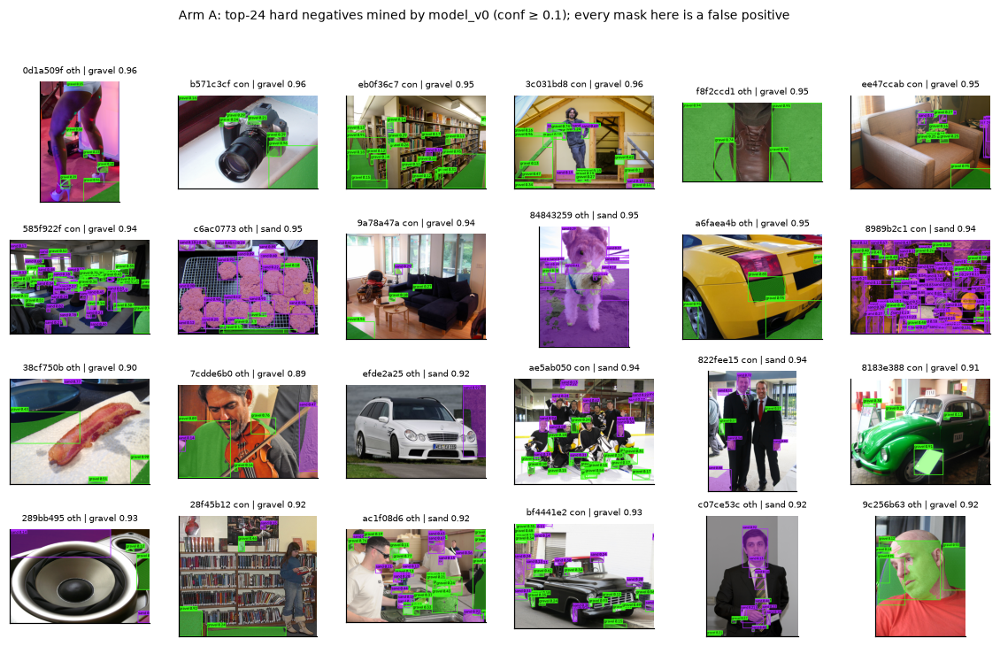

saved figure: outputs/05_hard_negative_mining/figures/fig02_hard_negatives_v0_armB.png|pdf


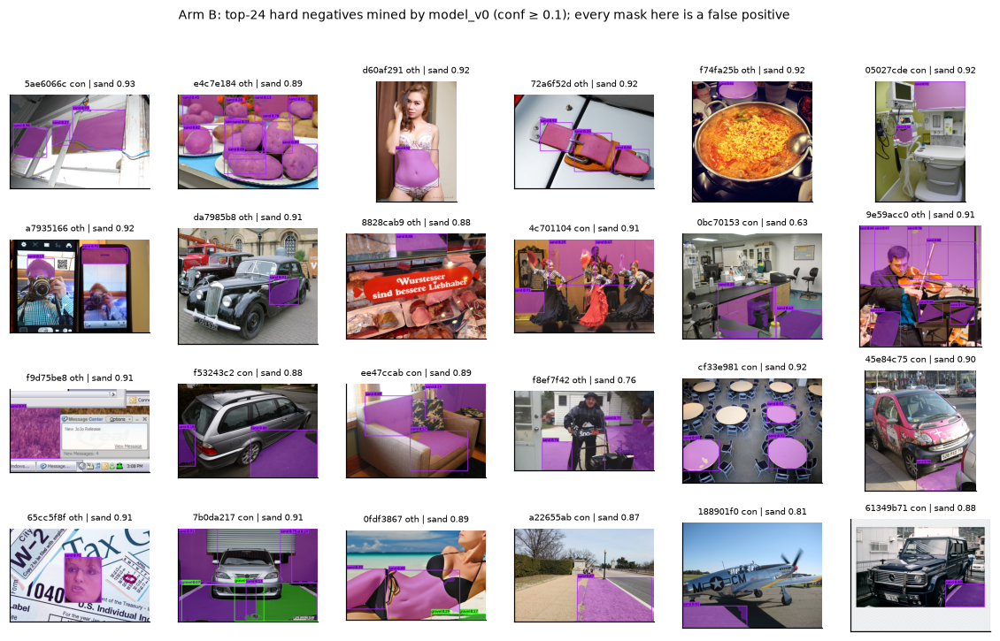

saved figure: outputs/05_hard_negative_mining/figures/fig02_hard_negatives_v0_armB640.png|pdf


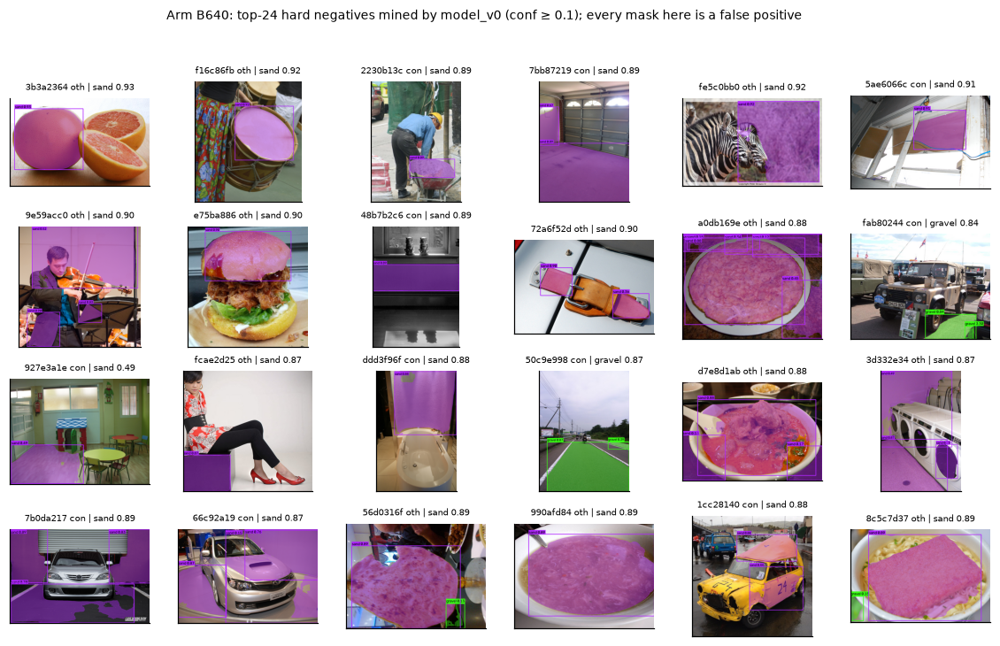

rejected by researcher so far: 0


In [16]:
# สีของผลทำนายบนภาพ (RGB): เขียวนีออน = gravel, ม่วง = sand — ตัดกับสีของหินและทรายจึงเห็นชัด
PRED_COLORS = {"gravel": (57, 255, 20), "sand": (176, 38, 255)}

def overlay_preds(img_bgr, model, imgsz, pp, conf_th, alpha=0.40):
    """mask โปร่งแสง + ขอบ mask + bounding box + ป้าย 'class conf' ของ detection ที่ผ่าน threshold ราย class"""
    x = pp(img_bgr) if pp is not None else img_bgr
    out = model.predict(x, imgsz=imgsz, conf=min(conf_th.values()), max_det=100, retina_masks=True, verbose=False)[0]
    vis = np.ascontiguousarray(img_bgr[..., ::-1]); info = []
    if out.masks is None:
        return vis, info
    H, W = vis.shape[:2]; lw = max(2, round(max(H, W) / 320)); fs = max(0.5, max(H, W) / 1100); ft = max(1, lw // 2)
    keep = [(m, int(c), float(s), b) for m, c, s, b in zip(out.masks.data.cpu().numpy(), out.boxes.cls.cpu().numpy(),
                                                           out.boxes.conf.cpu().numpy(), out.boxes.xyxy.cpu().numpy())
            if s >= conf_th[CLASS_NAMES[int(c)]]]
    layer = vis.copy()
    for m, c, s, b in keep:
        layer[m.astype(bool)] = PRED_COLORS[CLASS_NAMES[c]]
    vis = np.ascontiguousarray(cv2.addWeighted(layer, alpha, vis, 1 - alpha, 0))
    for m, c, s, b in sorted(keep, key=lambda t: t[2]):   # ป้ายของ conf สูงวาดทีหลังจึงอยู่ด้านบน
        name = CLASS_NAMES[c]; col = PRED_COLORS[name]; info.append((name, s))
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, cnts, -1, col, max(1, lw // 2))
        x0, y0, x1, y1 = [int(round(v)) for v in b]
        cv2.rectangle(vis, (x0, y0), (x1, y1), col, lw)
        label = f"{name} {s:.2f}"
        (tw, th_), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, fs, ft)
        ty = y0 - 4 if y0 - th_ - bl - 4 >= 0 else y0 + th_ + bl + 4
        cv2.rectangle(vis, (x0, ty - th_ - bl), (min(x0 + tw + 4, W - 1), ty + 2), col, -1)
        cv2.putText(vis, label, (x0 + 2, ty - bl + 1), cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 0, 0), ft, cv2.LINE_AA)
    return vis, info

mined_ids = {}
for arm in ARMS:
    neg_r1 = json.loads((ROOT / "data" / "hnm" / f"{arm}_f9" / "r1" / "negatives.json").read_text())["neg_image_ids"]
    mined_ids[arm] = neg_r1
    m = YOLO(str(ARMS[arm]["v0"])); th = MODELS[(arm, "v0")]["conf_th"]
    sel = NEG.set_index("image_id").loc[neg_r1[:24]]
    fig, axes = plt.subplots(4, 6, figsize=(13, 7.4))
    for ax, (iid, r) in zip(axes.ravel(), sel.iterrows()):
        vis, info = overlay_preds(cap_side(cv2.imread(r.path)), m, ARMS[arm]["imgsz"], ARMS[arm]["pp"], {c: MINE_CONF for c in CLASS_NAMES})
        ax.imshow(vis); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        top = max(info, key=lambda t: t[1]) if info else ("-", 0)
        ax.set_title(f"{r.oi_id[:8]} {r.kind[:3]} | {top[0]} {top[1]:.2f}", fontsize=6.5)
    fig.suptitle(f"Arm {arm}: top-24 hard negatives mined by model_v0 (conf ≥ {MINE_CONF}); every mask here is a false positive", fontsize=9)
    savefig(fig, FIG / f"fig02_hard_negatives_v0_arm{arm}"); plt.show()
print("rejected by researcher so far:", len(REJECTS))

### 4.4 ลักษณะของภาพลบที่ทายผิด

**Method** เปรียบเทียบอัตราการทายผิดของ model_v0 บน mining pool แยกตามชนิดของภาพ (context / other) และตาม label ของฉาก เพื่อดูว่า FP กระจุกในฉากประเภทใด

saved table: outputs/05_hard_negative_mining/tables/v0_pool_fp_by_scene.csv (30 rows)


saved figure: outputs/05_hard_negative_mining/figures/fig03_v0_fp_by_scene.png|pdf


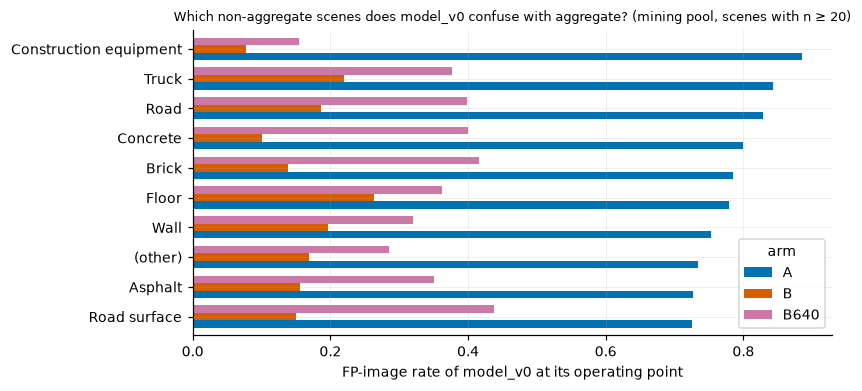

In [17]:
rows = []
for arm in ARMS:
    D = POOL_DETS[(arm, "v0")]; th = MODELS[(arm, "v0")]["conf_th"]
    D = D[D.conf >= D.cls.map({i: th[c] for i, c in enumerate(CLASS_NAMES)})]
    P = NEG_R["pool"].assign(fp=lambda d: d.image_id.isin(set(D.image_id)))
    for lab in CONTEXT + ["(other)"]:
        sub = P[P.kind == "other"] if lab == "(other)" else P[P.context_labels.fillna("").str.split("|").apply(lambda s: lab in s)]
        if len(sub) >= 20:
            rows.append(dict(arm=arm, scene=lab, n=len(sub), fp_img_rate=sub.fp.mean()))
SCN = pd.DataFrame(rows); save_table(SCN, TAB / "v0_pool_fp_by_scene.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pv = SCN.pivot(index="scene", columns="arm", values="fp_img_rate").sort_values("A")
pv.plot.barh(ax=ax, color=["#0072B2", "#D55E00", "#CC79A7"][:len(ARMS)], width=0.75)
ax.set_xlabel("FP-image rate of model_v0 at its operating point"); ax.set_ylabel("")
ax.set_title("Which non-aggregate scenes does model_v0 confuse with aggregate? (mining pool, scenes with n ≥ 20)", fontsize=8.5)
savefig(fig, FIG / "fig03_v0_fp_by_scene"); plt.show()

## 5. การเลือกแบบจำลอง (กำหนดล่วงหน้า)

**กฎ** สำหรับแต่ละ arm ผู้สมัครคือ v0 และ (freeze 9, 11) × (รอบ 1, 2, 3) รวม 7 ตัว

1. ตัดผู้สมัครที่ val mask AP50-95 ต่ำกว่าของ v0 เกิน 0.01 (non-inferiority margin หนึ่งจุด)
2. เลือกตัวที่ `negval_fp_img_rate` ต่ำที่สุด ถ้าเท่ากันเลือกตัวที่ val mask AP สูงกว่า

**Rationale** เป้าหมายของ hard negative mining คือลด FP โดยไม่เสียความสามารถหลัก จึงกำหนดความแม่นยำเป็นเงื่อนไขขั้นต่ำและ FP เป็นเป้าหมาย ทั้งสองค่ามาจากชุดที่ไม่ใช่ชุดรายงานผล ระยะ 0.01 ใกล้เคียงกับความแปรปรวนระหว่าง seed ที่พบใน Notebook 03 จึงถือว่าความต่างที่น้อยกว่านี้แยกจากสัญญาณรบกวนไม่ได้

**ผลของ freeze** เปรียบเทียบ freeze 9 กับ 11 ในรอบเดียวกันด้วยค่า neg-val และ val ทั้งหมด (ไม่ใช่เฉพาะตัวที่ถูกเลือก)

In [18]:
CAND_DF = pd.DataFrame([MODELS[k] for k in sorted(MODELS, key=lambda k: (k[0], MODELS[k]["round"], str(MODELS[k]["freeze"])))])
for c in ("conf_th", "state_th", "state_th_negcal"):
    CAND_DF[c] = CAND_DF[c].apply(json.dumps)
MARGIN = 0.01
SELECTED = {}
for arm, g in CAND_DF.groupby("arm"):
    base = g[g.tag == "v0"].val_mask_AP.iloc[0]
    ok = g[g.val_mask_AP >= base - MARGIN].sort_values(["negval_fp_img_rate", "val_mask_AP"], ascending=[True, False])
    SELECTED[arm] = ok.tag.iloc[0]
    CAND_DF.loc[g.index, "eligible"] = g.val_mask_AP >= base - MARGIN
CAND_DF["selected"] = [SELECTED[a] == t for a, t in zip(CAND_DF.arm, CAND_DF.tag)]
save_table(CAND_DF, TAB / "candidates_val_negval.csv")
show = ["arm", "tag", "freeze", "round", "n_neg", "val_mask_AP", "val_mask_AP50", "val_mask_AP_gravel", "val_mask_AP_sand", "val_l2_macro_f1",
        "negval_fp_img_rate", "negval_fp_img_rate@0.25", "negval_fp_per_img", "negval_none_false_alarm", "negval_none_false_alarm_negcal",
        "negval_context_fp_img_rate", "negval_other_fp_img_rate", "eligible", "selected"]
display(CAND_DF[show].round(4))
print("selected:", SELECTED)
(OUT_ROOT / "selection.json").write_text(json.dumps(dict(rule="min negval_fp_img_rate s.t. val_mask_AP >= v0 - 0.01", margin=MARGIN,
    selected={a: dict(tag=t, weights=MODELS[(a, t)]["weights"], weights_sha256=sha256_file(MODELS[(a, t)]["weights"]),
                      conf_th=MODELS[(a, t)]["conf_th"], state_th=MODELS[(a, t)]["state_th"]) for a, t in SELECTED.items()},
    decided=time.strftime("%Y-%m-%dT%H:%M:%S%z")), indent=2))

saved table: outputs/05_hard_negative_mining/tables/candidates_val_negval.csv (21 rows)


,arm,tag,freeze,round,n_neg,val_mask_AP,val_mask_AP50,val_mask_AP_gravel,val_mask_AP_sand,val_l2_macro_f1,negval_fp_img_rate,negval_fp_img_rate@0.25,negval_fp_per_img,negval_none_false_alarm,negval_none_false_alarm_negcal,negval_context_fp_img_rate,negval_other_fp_img_rate,eligible,selected
0,A,v0,NaN,0,NaN,0.6424,0.8178,0.7841,0.5007,0.7245,0.773,0.821,3.614,0.642,0.088,0.804,0.742,True,True
1,A,f11_r1,11.0,1,178.0,0.5971,0.7741,0.7287,0.4656,0.4828,0.054,0.067,0.064,0.003,0.005,0.066,0.042,False,False
2,A,f9_r1,9.0,1,178.0,0.5950,0.7619,0.7513,0.4388,0.4784,0.014,0.024,0.014,0.006,0.005,0.012,0.016,False,False
3,A,f11_r2,11.0,2,356.0,0.5840,0.7491,0.7309,0.4371,0.4693,0.010,0.011,0.011,0.033,0.001,0.008,0.012,False,False
4,A,f9_r2,9.0,2,356.0,0.5924,0.7596,0.7495,0.4353,0.4505,0.009,0.014,0.009,0.018,0.004,0.008,0.010,False,False
5,A,f11_r3,11.0,3,450.0,0.5787,0.7490,0.7212,0.4361,0.4798,0.015,0.008,0.017,0.025,0.002,0.020,0.010,False,False
6,A,f9_r3,9.0,3,393.0,0.5933,0.7643,0.7204,0.4661,0.4854,0.003,0.006,0.005,0.009,0.002,0.002,0.004,False,False
7,B,v0,NaN,0,NaN,0.8245,0.9528,0.7576,0.8914,0.9257,0.184,0.497,0.223,0.706,0.125,0.206,0.162,True,False
8,B,f11_r1,11.0,1,176.0,0.8255,0.9487,0.7607,0.8904,0.9417,0.011,0.026,0.011,0.059,0.000,0.012,0.010,True,False
9,B,f9_r1,9.0,1,176.0,0.8158,0.9440,0.7531,0.8785,0.9184,0.002,0.019,0.002,0.027,0.000,0.002,0.002,True,False


selected: {'A': 'v0', 'B': 'f11_r3', 'B640': 'f11_r3'}


1527

saved figure: outputs/05_hard_negative_mining/figures/fig04_selection_tradeoff.png|pdf


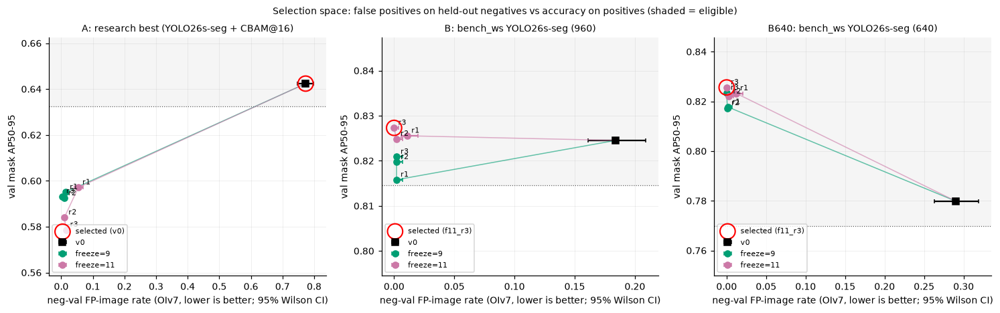

In [19]:
fig, axes = plt.subplots(1, len(ARMS), figsize=(5.5 * len(ARMS), 4.2))
FCOL = {9: "#009E73", 11: "#CC79A7"}
for ax, arm in zip(axes, ARMS):
    g = CAND_DF[CAND_DF.arm == arm]; v0 = g[g.tag == "v0"].iloc[0]
    ax.axhspan(v0.val_mask_AP - MARGIN, v0.val_mask_AP + 1, color="#000000", alpha=0.04, lw=0)
    ax.axhline(v0.val_mask_AP - MARGIN, color="#555555", ls=":", lw=0.8)
    ax.errorbar(v0.negval_fp_img_rate, v0.val_mask_AP, xerr=[[v0.negval_fp_img_rate - v0.negval_fp_img_rate_lo], [v0.negval_fp_img_rate_hi - v0.negval_fp_img_rate]],
                fmt="s", color="black", ms=7, capsize=2, label="v0")
    for F in FREEZES:
        s = pd.concat([g[g.tag == "v0"], g[g.freeze == F].sort_values("round")])
        ax.plot(s.negval_fp_img_rate, s.val_mask_AP, "-", color=FCOL[F], lw=1, alpha=0.6)
        r = s[s.tag != "v0"]
        ax.errorbar(r.negval_fp_img_rate, r.val_mask_AP, xerr=[r.negval_fp_img_rate - r.negval_fp_img_rate_lo, r.negval_fp_img_rate_hi - r.negval_fp_img_rate],
                    fmt="o", color=FCOL[F], ms=6, capsize=2, label=f"freeze={F}")
        for x in r.itertuples():
            ax.annotate(f"r{x.round}", (x.negval_fp_img_rate, x.val_mask_AP), xytext=(4, 3), textcoords="offset points", fontsize=7)
    sel = g[g.selected].iloc[0]
    ax.scatter(sel.negval_fp_img_rate, sel.val_mask_AP, s=220, facecolors="none", edgecolors="red", lw=1.4, label=f"selected ({sel.tag})", zorder=5)
    ax.set_xlabel("neg-val FP-image rate (OIv7, lower is better; 95% Wilson CI)"); ax.set_ylabel("val mask AP50-95")
    ax.set_title(ARMS[arm]["label"], fontsize=9); ax.legend(fontsize=7, loc="lower left")
    ax.set_ylim(min(g.val_mask_AP.min(), v0.val_mask_AP - MARGIN) - 0.02, g.val_mask_AP.max() + 0.02)
fig.suptitle("Selection space: false positives on held-out negatives vs accuracy on positives (shaded = eligible)", fontsize=9)
savefig(fig, FIG / "fig04_selection_tradeoff"); plt.show()

saved figure: outputs/05_hard_negative_mining/figures/fig05_training_curves.png|pdf


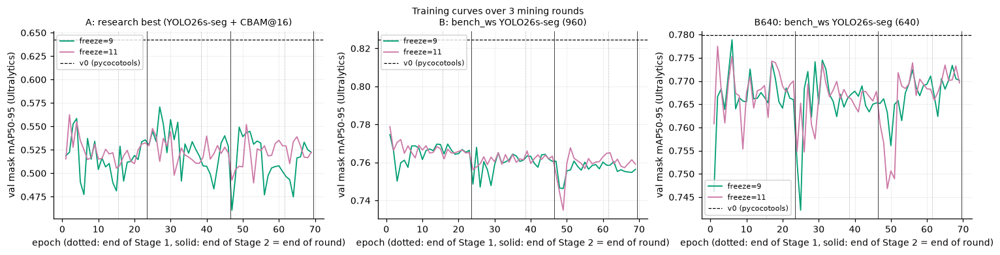

In [20]:
# เส้นการฝึกของทุก run (val mask mAP50-95 ต่อ epoch ต่อเนื่องกันทุกรอบและทุกขั้น)
fig, axes = plt.subplots(1, len(ARMS), figsize=(5.5 * len(ARMS), 3.4), sharey=False)
for ax, arm in zip(axes, ARMS):
    for F in FREEZES:
        xs, ys, off, bounds = [], [], 0, []
        for k in range(1, N_ROUNDS + 1):
            for s in (1, 2):
                rd = RUNS / f"{arm}_f{F}" / f"r{k}_s{s}"
                e = pd.read_csv(rd / "results.csv"); e.columns = [c.strip() for c in e.columns]
                xs += list(off + e.epoch); ys += list(e["metrics/mAP50-95(M)"]); off += len(e); bounds.append((off, s))
        ax.plot(xs, ys, color=FCOL[F], lw=1.2, label=f"freeze={F}")
    for b, s in bounds:
        ax.axvline(b + 0.5, color="#999999" if s == 1 else "#333333", lw=0.6, ls=":" if s == 1 else "-")
    ax.axhline(MODELS[(arm, "v0")]["val_mask_AP"], color="black", ls="--", lw=0.8, label="v0 (pycocotools)")
    ax.set_xlabel("epoch (dotted: end of Stage 1, solid: end of Stage 2 = end of round)"); ax.set_ylabel("val mask mAP50-95 (Ultralytics)")
    ax.set_title(ARMS[arm]["label"], fontsize=9); ax.legend(fontsize=7)
fig.suptitle("Training curves over 3 mining rounds", fontsize=9)
savefig(fig, FIG / "fig05_training_curves"); plt.show()

## 6. การประเมินบนชุดรายงานผล

**Protocol** ประเมินผู้สมัครทุกตัว (ไม่ใช่เฉพาะตัวที่ถูกเลือก) ด้วย threshold ที่เลือกจาก val ของตัวมันเอง เพื่อแสดงแนวโน้มตามรอบอย่างโปร่งใส แต่ข้อสรุปหลักใช้เฉพาะคู่ v0 กับตัวที่ถูกเลือกในหัวข้อ 5

- neg-test: FP-image rate, FP ต่อภาพ, none false alarm (Wilson 95% CI) และผลต่างแบบคู่ของ FP-image rate (McNemar exact test บนภาพเดียวกัน)
- dev test (arm A) และ holdout: mask AP50-95 พร้อม cluster bootstrap 95% CI 1,000 รอบ, AP ราย class, recall ที่ operating point, macro-F1 ของสถานะ
- S02: สัดส่วนของสถานะที่ทำนาย และ detection ต่อภาพที่ operating point

In [21]:
from scipy.stats import binomtest
REPORT_SETS = {"A": ["devtest", "piled_materials", "separate_rock_sand"], "B": ["piled_materials", "separate_rock_sand"],
               "B640": ["piled_materials", "separate_rock_sand"]}
REP, NEGTEST_D = [], {}
for (arm, tag), M in sorted(MODELS.items(), key=lambda kv: (kv[0][0], kv[1]["round"], str(kv[1]["freeze"]))):
    A = ARMS[arm]; w = M["weights"]; row = dict(arm=arm, tag=tag, freeze=M["freeze"], round=M["round"], selected=SELECTED[arm] == tag)
    Dn = cached_neg(CACHE / "neg" / arm / f"{tag}__negtest.csv.gz", lambda: neg_detections(w, NEG_R["negtest"], A["imgsz"], A["pp"], desc=f"{tag} negtest"))
    NEGTEST_D[(arm, tag)] = Dn
    row.update(neg_metrics(Dn, NEG_R["negtest"], M["conf_th"], M["state_th"], "negtest_", M["state_th_negcal"]))
    for kind in ("context", "other"):
        row.update(neg_metrics(Dn, NEG_R["negtest"][NEG_R["negtest"].kind == kind], M["conf_th"], M["state_th"], f"negtest_{kind}_", M["state_th_negcal"]))
    for s in REPORT_SETS[arm]:
        R = EVALSETS[arm][s]["R"]; dets, res = eval_positive(tag, arm, w, s)
        l2, _ = l2_evaluate(state_scores(dets, R), R, M["state_th"]); boot = bootstrap_mask_ap(res, R, 1000)
        l2c, _ = l2_evaluate(state_scores(dets, R), R, M["state_th_negcal"])
        rec = {c: operating_point(res["segm"]["recs"], R.image_id.astype(int).tolist(), i + 1, thresholds=[M["conf_th"][c]]).iloc[0]
               for i, c in enumerate(CLASS_NAMES)}
        st = res["segm"]["stats"]; pc = res["segm"]["per_class"]
        row.update({f"{s}_mask_AP": np.nanmean([pc[c]["AP"] for c in CLASS_NAMES]), f"{s}_mask_AP_lo": boot["ci_low"], f"{s}_mask_AP_hi": boot["ci_high"],
                    f"{s}_mask_AP_coco": st["AP"], f"{s}_mask_AP50": st["AP50"],
                    **{f"{s}_AP_{c}": pc[c]["AP"] for c in CLASS_NAMES}, **{f"{s}_recall_{c}": rec[c].recall for c in CLASS_NAMES},
                    **{f"{s}_precision_{c}": rec[c].precision for c in CLASS_NAMES}, f"{s}_l2_macro_f1": l2["macro_f1"],
                    f"{s}_l2_macro_f1_negcal": l2c["macro_f1"]})
    dets = cached_dets(det_cache(tag, arm, "s02"), lambda: predict_dets(w, S02_R, imgsz=A["imgsz"], transform=A["pp"], desc=f"{tag} s02"))
    sc = state_scores(dets, S02_R)
    stt = states_from_presence(sc.S_gravel.values >= M["state_th"]["gravel"], sc.S_sand.values >= M["state_th"]["sand"])
    row.update({f"s02_frac_{x}": float((stt == x).mean()) for x in STATES})
    row["s02_dets_per_img"] = sum(d["score"] >= M["conf_th"][CLASS_NAMES[d["category_id"] - 1]] for d in dets) / len(S02_R)
    REP.append(row)
REP = pd.DataFrame(REP); save_table(REP, TAB / "report_all_candidates.csv")

# ผลต่างแบบคู่ v0 → selected บน neg-test (McNemar exact บนภาพเดียวกัน)
PAIR = []
for arm in ARMS:
    t = SELECTED[arm]; ids = NEG_R["negtest"].image_id
    def fp_set(tag):
        D = NEGTEST_D[(arm, tag)]; th = MODELS[(arm, tag)]["conf_th"]
        return set(D[D.conf >= D.cls.map({i: th[c] for i, c in enumerate(CLASS_NAMES)})].image_id)
    a, b = fp_set("v0"), fp_set(t)
    n01, n10 = len(b - a), len(a - b)   # 01: ใหม่ผิด เดิมถูก; 10: เดิมผิด ใหม่ถูก
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    PAIR.append(dict(arm=arm, selected=t, n=len(ids), v0_fp_images=len(a), selected_fp_images=len(b), fixed=n10, newly_wrong=n01,
                     diff_rate=(len(b) - len(a)) / len(ids), mcnemar_exact_p=p))
PAIR = pd.DataFrame(PAIR); save_table(PAIR, TAB / "negtest_paired_v0_vs_selected.csv"); display(PAIR)

saved table: outputs/05_hard_negative_mining/tables/report_all_candidates.csv (21 rows)
saved table: outputs/05_hard_negative_mining/tables/negtest_paired_v0_vs_selected.csv (3 rows)


,arm,selected,n,v0_fp_images,selected_fp_images,fixed,newly_wrong,diff_rate,mcnemar_exact_p
0,A,v0,1500,1134,1134,0,0,0.000000,1.000000e+00
1,B,f11_r3,1500,244,0,244,0,-0.162667,7.074749e-74
2,B640,f11_r3,1500,438,0,438,0,-0.292000,2.817681e-132


In [22]:
cols = ["arm", "tag", "selected", "negtest_fp_img_rate", "negtest_fp_img_rate_lo", "negtest_fp_img_rate_hi", "negtest_fp_per_img",
        "negtest_none_false_alarm", "negtest_none_false_alarm_negcal", "negtest_context_fp_img_rate", "negtest_other_fp_img_rate"]
display(REP[cols].round(4))
pos_cols = ["arm", "tag", "selected"] + [c for c in REP.columns if any(c.startswith(s) for s in ("devtest_", "piled_", "separate_"))
                                          and any(c.endswith(x) for x in ("mask_AP", "mask_AP_lo", "mask_AP_hi", "AP_gravel", "AP_sand", "recall_gravel", "recall_sand", "l2_macro_f1", "l2_macro_f1_negcal"))]
display(REP[pos_cols].round(4))
display(REP[["arm", "tag"] + [c for c in REP.columns if c.startswith("s02_")]].round(3))

,arm,tag,selected,negtest_fp_img_rate,negtest_fp_img_rate_lo,negtest_fp_img_rate_hi,negtest_fp_per_img,negtest_none_false_alarm,negtest_none_false_alarm_negcal,negtest_context_fp_img_rate,negtest_other_fp_img_rate
0,A,v0,True,0.7560,0.7336,0.7771,3.7233,0.6687,0.0800,0.7920,0.7200
1,A,f11_r1,False,0.0560,0.0455,0.0688,0.0633,0.0060,0.0087,0.0547,0.0573
2,A,f9_r1,False,0.0127,0.0081,0.0197,0.0180,0.0053,0.0047,0.0040,0.0213
3,A,f11_r2,False,0.0107,0.0066,0.0173,0.0107,0.0427,0.0060,0.0107,0.0107
4,A,f9_r2,False,0.0060,0.0032,0.0114,0.0067,0.0207,0.0040,0.0067,0.0053
5,A,f11_r3,False,0.0167,0.0113,0.0245,0.0167,0.0320,0.0007,0.0160,0.0173
6,A,f9_r3,False,0.0033,0.0014,0.0078,0.0053,0.0127,0.0027,0.0027,0.0040
7,B,v0,False,0.1627,0.1449,0.1822,0.2107,0.6853,0.1020,0.1880,0.1373
8,B,f11_r1,False,0.0080,0.0046,0.0139,0.0080,0.0527,0.0007,0.0093,0.0067
9,B,f9_r1,False,0.0000,0.0000,0.0026,0.0000,0.0327,0.0000,0.0000,0.0000


,arm,tag,selected,devtest_mask_AP,devtest_mask_AP_lo,devtest_mask_AP_hi,devtest_AP_gravel,devtest_AP_sand,devtest_recall_gravel,devtest_recall_sand,...,piled_materials_l2_macro_f1_negcal,separate_rock_sand_mask_AP,separate_rock_sand_mask_AP_lo,separate_rock_sand_mask_AP_hi,separate_rock_sand_AP_gravel,separate_rock_sand_AP_sand,separate_rock_sand_recall_gravel,separate_rock_sand_recall_sand,separate_rock_sand_l2_macro_f1,separate_rock_sand_l2_macro_f1_negcal
0,A,v0,True,0.5341,0.4137,0.7721,0.6378,0.4304,0.8232,0.7330,...,0.3152,0.0866,0.0436,0.1483,0.0523,0.1208,0.0717,0.1524,0.0462,0.0030
1,A,f11_r1,False,0.3599,0.2481,0.6074,0.5012,0.2186,0.4319,0.2524,...,0.2322,0.0228,0.0003,0.0615,0.0455,0.0001,0.0546,0.0000,0.0030,0.0030
2,A,f9_r1,False,0.3736,0.2425,0.6149,0.5126,0.2345,0.4609,0.3883,...,0.1712,0.0222,0.0017,0.0567,0.0444,0.0000,0.0341,0.0000,0.0030,0.0029
3,A,f11_r2,False,0.4072,0.2771,0.6351,0.5509,0.2635,0.3565,0.3155,...,0.0609,0.0237,0.0008,0.0583,0.0473,0.0000,0.0478,0.0000,0.0030,0.0029
4,A,f9_r2,False,0.3378,0.2314,0.6021,0.4537,0.2220,0.2725,0.2233,...,0.1373,0.0064,0.0008,0.0151,0.0129,0.0000,0.0068,0.0000,0.0028,0.0028
5,A,f11_r3,False,0.3057,0.1968,0.5964,0.4020,0.2093,0.2145,0.4078,...,0.0521,0.0274,0.0010,0.0639,0.0529,0.0020,0.0478,0.0000,0.0032,0.0030
6,A,f9_r3,False,0.2793,0.1356,0.6276,0.3018,0.2568,0.1565,0.4854,...,0.1196,0.0002,0.0000,0.0007,0.0004,0.0000,0.0000,0.0000,0.0027,0.0027
7,B,v0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.1545,0.0699,0.0406,0.1054,0.0647,0.0751,0.0512,0.0714,0.0693,0.0000
8,B,f11_r1,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0190,0.0029,0.0000,0.0099,0.0054,0.0004,0.0000,0.0000,0.0029,0.0027
9,B,f9_r1,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0200,0.0112,0.0003,0.0262,0.0224,0.0000,0.0068,0.0000,0.0029,0.0027


,arm,tag,s02_frac_none,s02_frac_gravel,s02_frac_sand,s02_frac_mixed,s02_dets_per_img
0,A,v0,0.000,0.606,0.000,0.394,1.182
1,A,f11_r1,1.000,0.000,0.000,0.000,0.000
2,A,f9_r1,1.000,0.000,0.000,0.000,0.000
3,A,f11_r2,0.970,0.000,0.030,0.000,0.000
4,A,f9_r2,0.985,0.000,0.015,0.000,0.000
5,A,f11_r3,1.000,0.000,0.000,0.000,0.000
6,A,f9_r3,1.000,0.000,0.000,0.000,0.000
7,B,v0,0.000,0.394,0.121,0.485,0.758
8,B,f11_r1,1.000,0.000,0.000,0.000,0.000
9,B,f9_r1,1.000,0.000,0.000,0.000,0.000


saved figure: outputs/05_hard_negative_mining/figures/fig06_report_by_round.png|pdf


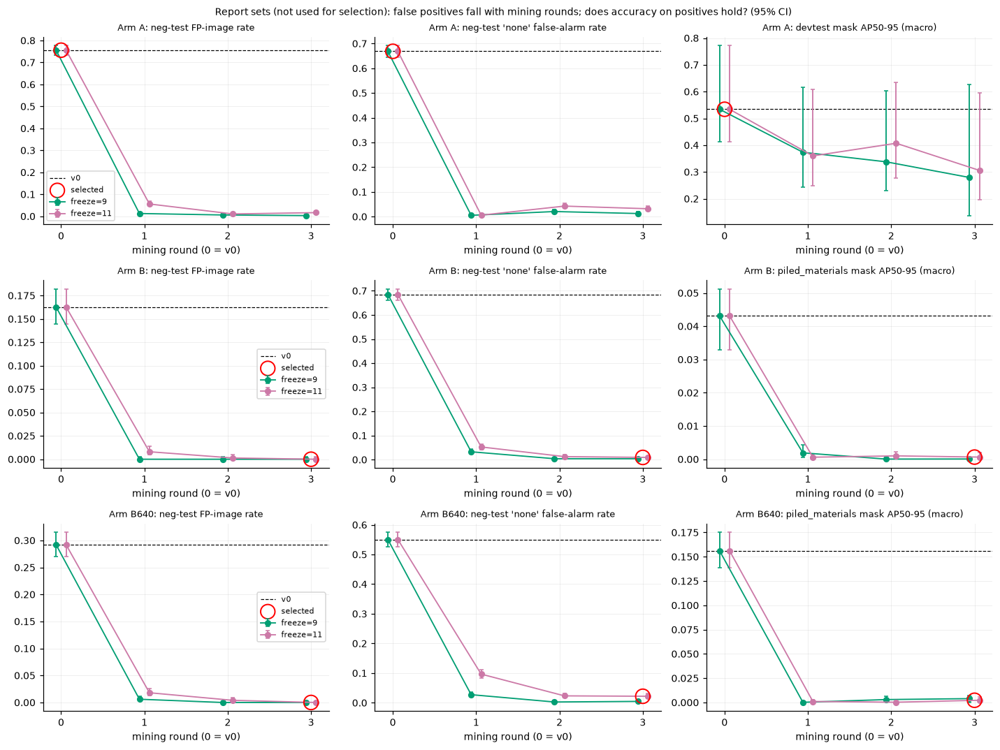

saved figure: outputs/05_hard_negative_mining/figures/fig07_positive_accuracy_v0_vs_selected.png|pdf


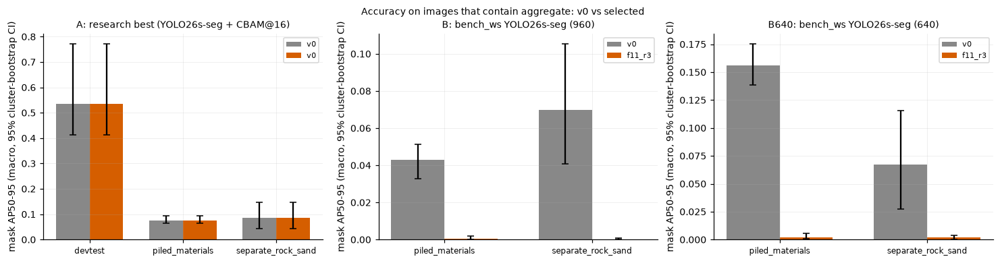

In [23]:
# ภาพสรุปหลัก: FP บนภาพลบ (neg-test) และความแม่นยำบนภาพที่มีวัสดุ ตามรอบ
fig, axes = plt.subplots(len(ARMS), 3, figsize=(13, 3.3 * len(ARMS)))
for r_, arm in enumerate(ARMS):
    g = REP[REP.arm == arm]; v0 = g[g.tag == "v0"].iloc[0]
    panels = [("negtest_fp_img_rate", "neg-test FP-image rate"), ("negtest_none_false_alarm", "neg-test 'none' false-alarm rate")]
    panels += [(f"{s}_mask_AP", f"{s} mask AP50-95 (macro)") for s in REPORT_SETS[arm][:1]]
    for ax, (m, lab) in zip(axes[r_], panels):
        ax.axhline(v0[m], color="black", ls="--", lw=0.8, label="v0")
        for F in FREEZES:
            s = pd.concat([g[g.tag == "v0"], g[g.freeze == F].sort_values("round")])
            lo, hi = s.get(f"{m}_lo"), s.get(f"{m}_hi")
            # ค่าประมาณจุดอาจอยู่นอกช่วง percentile ของ bootstrap เล็กน้อย จึงตัด error bar ที่ติดลบเป็นศูนย์
            yerr = None if lo is None else [(s[m] - lo).clip(lower=0), (hi - s[m]).clip(lower=0)]
            ax.errorbar(s["round"] + (0.06 if F == 11 else -0.06), s[m], yerr=yerr, fmt="-o", color=FCOL[F], ms=5, capsize=2, lw=1.2, label=f"freeze={F}")
        sel = g[g.selected].iloc[0]
        ax.scatter(sel["round"], sel[m], s=180, facecolors="none", edgecolors="red", lw=1.3, zorder=5, label="selected")
        ax.set_xticks(range(0, N_ROUNDS + 1)); ax.set_xlabel("mining round (0 = v0)"); ax.set_title(f"Arm {arm}: {lab}", fontsize=8.5)
    axes[r_][0].legend(fontsize=7)
fig.suptitle("Report sets (not used for selection): false positives fall with mining rounds; does accuracy on positives hold? (95% CI)", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig06_report_by_round"); plt.show()

fig, axes = plt.subplots(1, len(ARMS), figsize=(5.5 * len(ARMS), 3.6))
for ax, arm in zip(axes, ARMS):
    g = REP[REP.arm == arm].set_index("tag"); t = SELECTED[arm]
    sets = REPORT_SETS[arm]; x = np.arange(len(sets)); wdt = 0.36
    for j, (tg, col) in enumerate((("v0", "#888888"), (t, "#D55E00"))):
        v = [g.loc[tg, f"{s}_mask_AP"] for s in sets]
        e = [[max(g.loc[tg, f"{s}_mask_AP"] - g.loc[tg, f"{s}_mask_AP_lo"], 0) for s in sets], [max(g.loc[tg, f"{s}_mask_AP_hi"] - g.loc[tg, f"{s}_mask_AP"], 0) for s in sets]]
        ax.bar(x + (j - 0.5) * wdt, v, wdt, yerr=e, capsize=3, color=col, label=tg)
    ax.set_xticks(x); ax.set_xticklabels(sets, fontsize=8); ax.set_ylabel("mask AP50-95 (macro, 95% cluster-bootstrap CI)")
    ax.set_title(ARMS[arm]["label"], fontsize=9); ax.legend(fontsize=7)
fig.suptitle("Accuracy on images that contain aggregate: v0 vs selected", fontsize=9)
savefig(fig, FIG / "fig07_positive_accuracy_v0_vs_selected"); plt.show()

## 7. ตัวอย่างผลทำนายก่อนและหลัง (test visualization)

**Method** แสดงผลทำนายที่ operating point ของแต่ละแบบจำลองบนภาพเดียวกัน

1. ภาพ neg-test ที่ v0 ทายผิดด้วย conf สูงสุด เทียบกับแบบจำลองที่ถูกเลือก (คาดว่าแถวล่างควรว่าง)
2. ภาพ neg-test ที่แบบจำลองที่ถูกเลือกยังทายผิด (ข้อผิดพลาดที่เหลือ)
3. ภาพที่มีวัสดุจาก dev test (arm A) และ holdout แบบสุ่มด้วย seed คงที่ เพื่อดูว่าวัสดุจริงยังถูกตรวจพบ

การสุ่มภาพที่มีวัสดุทำก่อนดูผลและไม่ได้เลือกภาพที่ผลดี

viz models: {'A': 'f11_r1', 'B': 'f11_r3', 'B640': 'f11_r3'}


saved figure: outputs/05_hard_negative_mining/figures/viz/fig08_negtest_v0_fp_armA.png|pdf


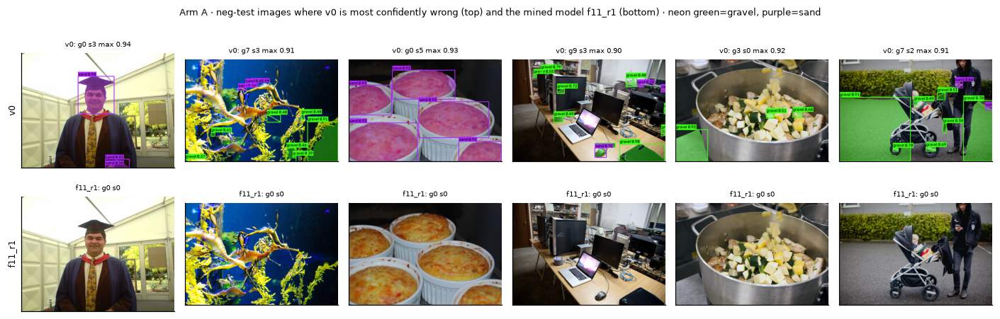

saved figure: outputs/05_hard_negative_mining/figures/viz/fig09_negtest_remaining_fp_armA.png|pdf


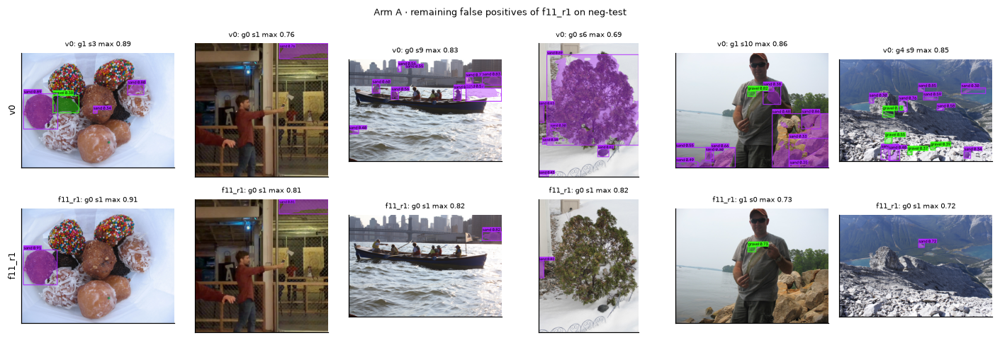

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_devtest_v0_vs_selected_armA.png|pdf


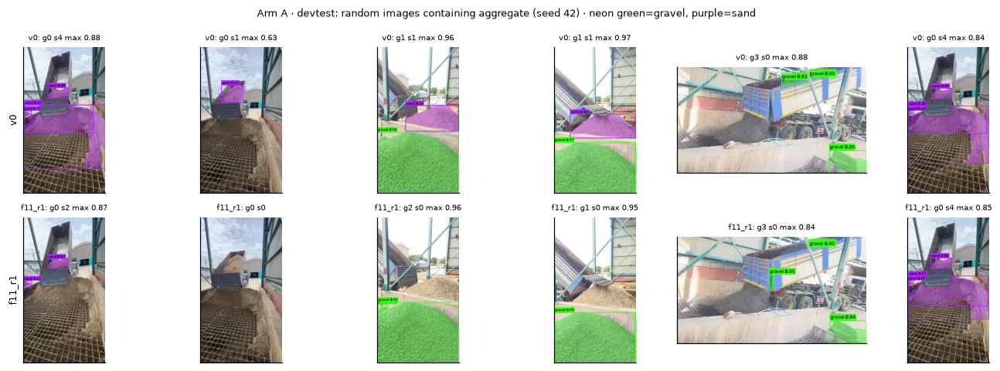

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_piled_materials_v0_vs_selected_armA.png|pdf


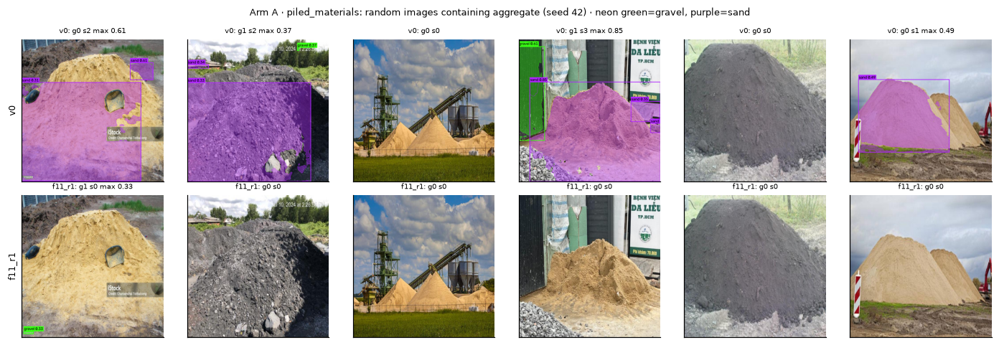

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_separate_rock_sand_v0_vs_selected_armA.png|pdf


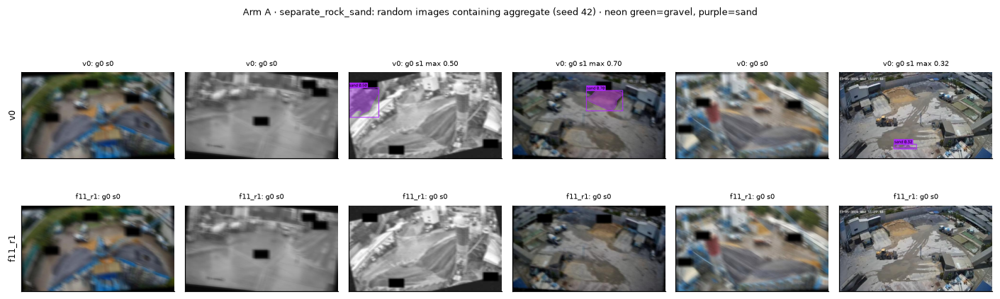

saved figure: outputs/05_hard_negative_mining/figures/viz/fig08_negtest_v0_fp_armB.png|pdf


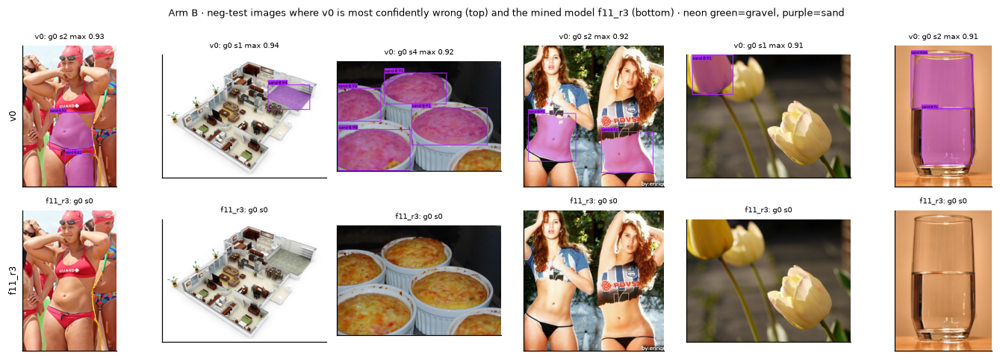

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_piled_materials_v0_vs_selected_armB.png|pdf


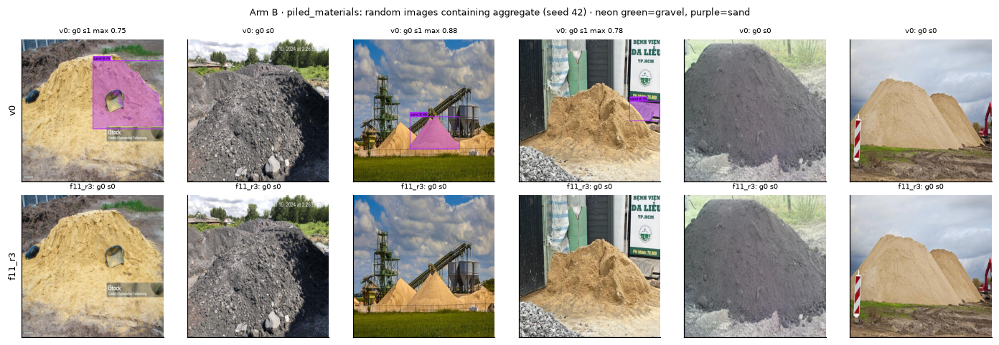

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_separate_rock_sand_v0_vs_selected_armB.png|pdf


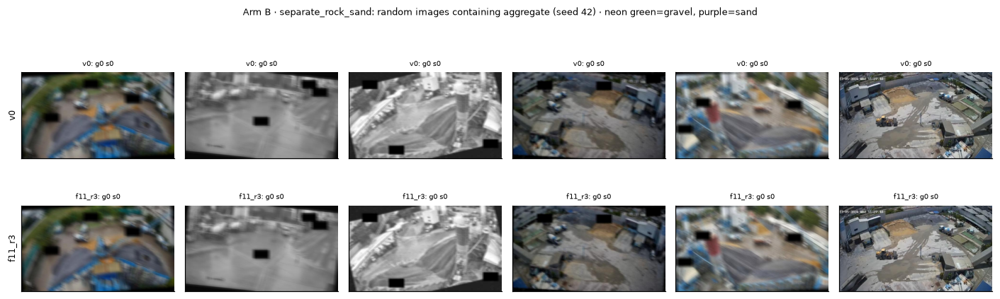

saved figure: outputs/05_hard_negative_mining/figures/viz/fig08_negtest_v0_fp_armB640.png|pdf


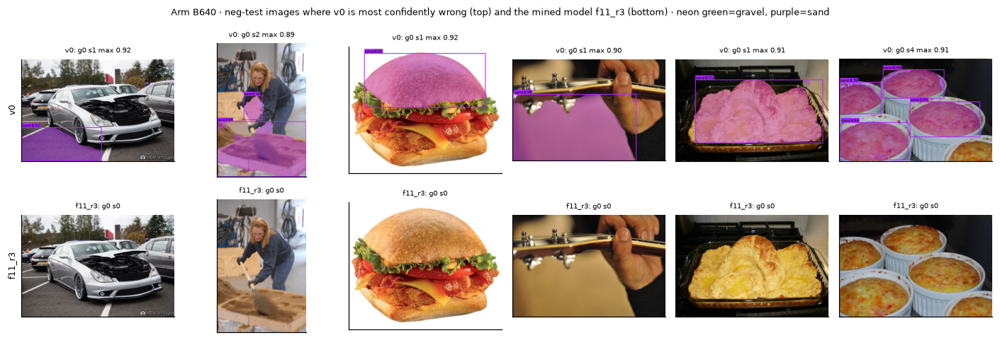

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_piled_materials_v0_vs_selected_armB640.png|pdf


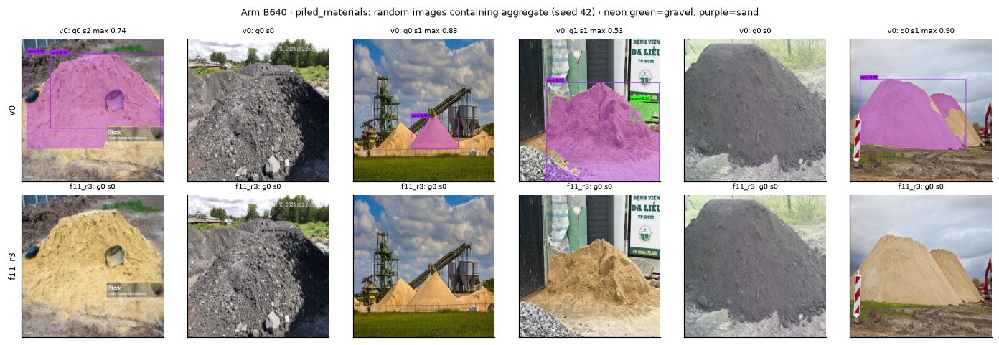

saved figure: outputs/05_hard_negative_mining/figures/viz/fig10_separate_rock_sand_v0_vs_selected_armB640.png|pdf


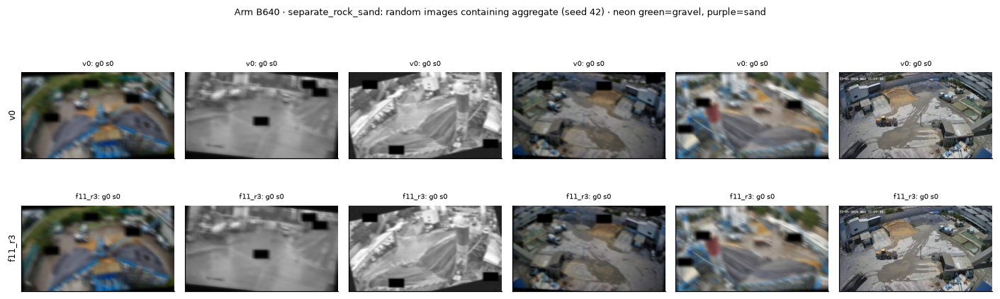

In [24]:
VIS = OUT_ROOT / "figures" / "viz"; VIS.mkdir(parents=True, exist_ok=True)
def compare_grid(arm, records, tags, title, path, ncol=6):
    models = {t: YOLO(str(MODELS[(arm, t)]["weights"])) for t in tags}
    fig, axes = plt.subplots(len(tags), ncol, figsize=(2.15 * ncol, 2.0 * len(tags) + 0.4), squeeze=False)
    for c, r in enumerate(records.head(ncol).itertuples()):
        img = cap_side(cv2.imread(r.path))
        for j, t in enumerate(tags):
            vis, info = overlay_preds(img, models[t], ARMS[arm]["imgsz"], ARMS[arm]["pp"], MODELS[(arm, t)]["conf_th"])
            ax = axes[j, c]; ax.imshow(vis); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            n_g = sum(1 for k, _ in info if k == "gravel"); n_s = len(info) - n_g
            ax.set_title(f"{t}: g{n_g} s{n_s}" + (f" max {max(s for _, s in info):.2f}" if info else ""), fontsize=6.5)
            if c == 0:
                ax.set_ylabel(t, fontsize=8)
    fig.suptitle(title, fontsize=8.5); fig.tight_layout(); savefig(fig, path); plt.show()

# แบบจำลองหลัง mining ที่นำมาแสดงภาพ: ตัวที่ถูกเลือก ถ้ากฎเลือก v0 (arm A) ใช้ตัวที่ val mask AP สูงสุดในบรรดาแบบจำลองหลัง mining
MINED_BEST = {a: g[g.tag != "v0"].sort_values("val_mask_AP", ascending=False).tag.iloc[0] for a, g in CAND_DF.groupby("arm")}
VIZ_TAG = {a: (SELECTED[a] if SELECTED[a] != "v0" else MINED_BEST[a]) for a in ARMS}
print("viz models:", VIZ_TAG)
for arm in ARMS:
    t = VIZ_TAG[arm]; NT = NEG_R["negtest"]
    def top_fp(tag, n=6):
        D = NEGTEST_D[(arm, tag)]; th = MODELS[(arm, tag)]["conf_th"]
        D = D[D.conf >= D.cls.map({i: th[c] for i, c in enumerate(CLASS_NAMES)})]
        ids = D.groupby("image_id").conf.max().sort_values(ascending=False).index[:n]
        return NT.set_index("image_id").loc[list(ids)].reset_index()
    compare_grid(arm, top_fp("v0"), ["v0", t], f"Arm {arm} · neg-test images where v0 is most confidently wrong (top) and the mined model {t} (bottom) · neon green=gravel, purple=sand",
                 VIS / f"fig08_negtest_v0_fp_arm{arm}")
    r_left = top_fp(t)
    if len(r_left):
        compare_grid(arm, r_left, ["v0", t], f"Arm {arm} · remaining false positives of {t} on neg-test", VIS / f"fig09_negtest_remaining_fp_arm{arm}")
    for s in REPORT_SETS[arm]:
        R = EVALSETS[arm][s]["R"]; R = R[R.state != "none"].sample(6, random_state=SEED)
        compare_grid(arm, R, ["v0", t], f"Arm {arm} · {s}: random images containing aggregate (seed {SEED}) · neon green=gravel, purple=sand",
                     VIS / f"fig10_{s}_v0_vs_selected_arm{arm}")

## 8. สรุปผล

เซลล์ต่อไปนี้รวมตัวเลขหลักของ v0 และแบบจำลองที่ถูกเลือกของแต่ละ arm ไว้ในตารางเดียว (`tables/summary_v0_vs_selected.csv`) การอภิปรายผลอยู่ในเซลล์ Markdown ถัดไป

In [25]:
KEYS = ["negval_fp_img_rate", "negtest_fp_img_rate", "negtest_fp_per_img", "negtest_none_false_alarm", "negtest_none_false_alarm_negcal",
        "piled_materials_l2_macro_f1", "piled_materials_l2_macro_f1_negcal", "negtest_context_fp_img_rate",
        "negtest_other_fp_img_rate", "val_mask_AP", "devtest_mask_AP", "piled_materials_mask_AP", "separate_rock_sand_mask_AP",
        "piled_materials_recall_gravel", "piled_materials_recall_sand", "separate_rock_sand_recall_gravel", "separate_rock_sand_recall_sand",
        "s02_frac_none"]
ALL = REP.merge(CAND_DF[["arm", "tag", "val_mask_AP", "negval_fp_img_rate"]], on=["arm", "tag"])
SUM = []
for arm in ARMS:
    for tg in ("v0", SELECTED[arm]):
        r = ALL[(ALL.arm == arm) & (ALL.tag == tg)].iloc[0]
        SUM.append(dict(arm=arm, model=tg, **{k: r.get(k, np.nan) for k in KEYS}))
SUM = pd.DataFrame(SUM); save_table(SUM, TAB / "summary_v0_vs_selected.csv")
display(SUM.set_index(["arm", "model"]).T.round(4))
(OUT_ROOT / "summary.json").write_text(json.dumps(dict(selected=SELECTED, summary=SUM.to_dict("records"), paired=PAIR.to_dict("records"),
                                                       finished=time.strftime("%Y-%m-%dT%H:%M:%S%z")), indent=2, default=float))

saved table: outputs/05_hard_negative_mining/tables/summary_v0_vs_selected.csv (6 rows)


arm                                      A               B            B640  \
model                                   v0      v0      v0  f11_r3      v0   
negval_fp_img_rate                  0.7730  0.7730  0.1840  0.0000  0.2900   
negtest_fp_img_rate                 0.7560  0.7560  0.1627  0.0000  0.2920   
negtest_fp_per_img                  3.7233  3.7233  0.2107  0.0000  0.3940   
negtest_none_false_alarm            0.6687  0.6687  0.6853  0.0093  0.5507   
negtest_none_false_alarm_negcal     0.0800  0.0800  0.1020  0.0000  0.1600   
piled_materials_l2_macro_f1         0.3163  0.3163  0.3458  0.0300  0.3688   
piled_materials_l2_macro_f1_negcal  0.3152  0.3152  0.1545  0.0185  0.2892   
negtest_context_fp_img_rate         0.7920  0.7920  0.1880  0.0000  0.3360   
negtest_other_fp_img_rate           0.7200  0.7200  0.1373  0.0000  0.2480   
val_mask_AP                         0.6424  0.6424  0.8245  0.8273  0.7799   
devtest_mask_AP                     0.5341  0.5341     NaN     NaN     NaN   
piled_materials_mask_AP             0.0754  0.0754  0.0431  0.0006  0.1561   
separate_rock_sand_mask_AP          0.0866  0.0866  0.0699  0.0001  0.0670   
piled_materials_recall_gravel       0.2543  0.2543  0.0497  0.0000  0.3499   
piled_materials_recall_sand         0.4491  0.4491  0.0904  0.0000  0.3214   
separate_rock_sand_recall_gravel    0.0717  0.0717  0.0512  0.0000  0.0819   
separate_rock_sand_recall_sand      0.1524  0.1524  0.0714  0.0000  0.0762   
s02_frac_none                       0.0000  0.0000  0.0000  1.0000  0.0000   

arm                                         
model                               f11_r3  
negval_fp_img_rate                  0.0000  
negtest_fp_img_rate                 0.0000  
negtest_fp_per_img                  0.0000  
negtest_none_false_alarm            0.0220  
negtest_none_false_alarm_negcal     0.0007  
piled_materials_l2_macro_f1         0.0402  
piled_materials_l2_macro_f1_negcal  0.0188  
negtest_context_fp_img_rate         0.0000  
negtest_other_fp_img_rate           0.0000  
val_mask_AP                         0.8256  
devtest_mask_AP                        NaN  
piled_materials_mask_AP             0.0023  
separate_rock_sand_mask_AP          0.0020  
piled_materials_recall_gravel       0.0000  
piled_materials_recall_sand         0.0000  
separate_rock_sand_recall_gravel    0.0000  
separate_rock_sand_recall_sand      0.0000  
s02_frac_none                       1.0000

6378

### 8.1 ผลการประเมินแบบเต็มบนชุดทดสอบ เมื่อใช้แบบจำลองหลัง mining

**Method** ประเมินแบบจำลองทุกตัว (v0 และแบบจำลองหลัง mining ทุก run ทุกรอบ) บนชุดทดสอบทุกชุดด้วย protocol เดียวกับ Notebook 03.5 และ 04 และรายงานทุกค่าที่ evaluator คำนวณได้ ค่าใน cell นี้คำนวณจาก detection ที่ cache ไว้แล้ว จึงไม่มีการรัน inference เพิ่ม

| กลุ่มค่า | รายละเอียด |
|---|---|
| L1 instance (3 protocol) | `scope` (protocol หลัก), `ignore` และ `strict` × mask/box × COCO 12 ค่า (AP, AP50, AP75, AP_S/M/L, AR1/10/100, AR_S/M/L) และ AP, AP50 ราย class |
| ช่วงความเชื่อมั่น | mask AP50-95 macro พร้อม cluster bootstrap 95% CI (1,000 รอบ) |
| Operating point | ราย class: conf threshold, TP, FP, FN, precision, recall, F1 ที่ IoU 0.5 |
| L2 สถานะของภาพ | accuracy, balanced accuracy, macro-F1, Cohen's κ, presence AP ราย class, confusion matrix และ macro-F1/balanced accuracy เมื่อใช้ θ ที่เลือกด้วยภาพลบ (negcal) |
| neg-test | FP-image rate, FP-image rate@0.25, FP ต่อภาพ, none false alarm (และ negcal) พร้อม Wilson 95% CI แยก context/other |

ชุดที่ใช้: dev test (เฉพาะ arm A), holdout Piled Materials, holdout Separate Rock-Sand และ neg-test ตาราง long-format ทั้งหมดอยู่ใน `tables/full_test_eval_long.csv` และแบบกว้างราย (arm, ชุด) อยู่ใน `tables/full_test_eval_<arm>_<set>.csv`

In [26]:
FULL = []
for (arm, tag), M in sorted(MODELS.items(), key=lambda kv: (kv[0][0], kv[1]["round"], str(kv[1]["freeze"]))):
    rep_row = REP[(REP.arm == arm) & (REP.tag == tag)].iloc[0]
    base = dict(arm=arm, model=tag, freeze=M["freeze"], round=M["round"], n_neg_train=M.get("n_neg"), selected=SELECTED[arm] == tag)
    for s in REPORT_SETS[arm]:
        E = EVALSETS[arm][s]; R = E["R"]; ids = R.image_id.astype(int).tolist()
        dets, res = eval_positive(tag, arm, M["weights"], s)
        row = dict(**base, set=s, images=len(R), clusters=R.group_merged.nunique(), detections=len(dets),
                   mask_AP_macro=rep_row[f"{s}_mask_AP"], mask_AP_macro_ci_low=rep_row[f"{s}_mask_AP_lo"], mask_AP_macro_ci_high=rep_row[f"{s}_mask_AP_hi"])
        for proto, rr in (("scope", res), ("ignore", l1_evaluate(E["gt"], dets, R, "ignore")), ("strict", l1_evaluate(E["gt"], dets, R, "strict"))):
            for it, tg in (("segm", "mask"), ("bbox", "box")):
                row.update({f"{proto}_{tg}_{k}": v for k, v in rr[it]["stats"].items()})
                for c, v in rr[it]["per_class"].items():
                    row[f"{proto}_{tg}_AP_{c}"] = v["AP"]; row[f"{proto}_{tg}_AP50_{c}"] = v["AP50"]
        for i, c in enumerate(CLASS_NAMES):
            op = operating_point(res["segm"]["recs"], ids, i + 1, thresholds=[M["conf_th"][c]]).iloc[0]
            row.update({f"op_{c}_{k}": op[k] for k in ("conf", "TP", "FP", "FN", "precision", "recall", "F1")})
        sc = state_scores(dets, R)
        for nm, th in (("L2", M["state_th"]), ("L2negcal", M["state_th_negcal"])):
            l2, _ = l2_evaluate(sc, R, th)
            row.update({f"{nm}_{k}": l2[k] for k in ("accuracy", "balanced_accuracy", "macro_f1", "kappa", "presence_AP_gravel", "presence_AP_sand")})
            row[f"{nm}_confusion"] = json.dumps(dict(labels=l2["labels"], matrix=l2["confusion"]))
        FULL.append(row)
    nt = {k[len("negtest_"):]: v for k, v in rep_row.items() if k.startswith("negtest_")}
    FULL.append(dict(**base, set="negtest", images=len(NEG_R["negtest"]), clusters=len(NEG_R["negtest"]), **nt))
FULL = pd.DataFrame(FULL); save_table(FULL, TAB / "full_test_eval_long.csv")

pd.set_option("display.max_rows", 400)
for (arm, s), g in FULL.groupby(["arm", "set"], sort=False):
    W = g.set_index("model").dropna(axis=1, how="all").drop(columns=["arm", "set"]).T
    save_table(W.reset_index().rename(columns={"index": "metric"}), TAB / f"full_test_eval_{arm}_{s}.csv")
    print(f"\n===== Arm {arm} · {s} (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====")
    display(W.map(lambda v: round(v, 4) if isinstance(v, (float, np.floating)) else v))

saved table: outputs/05_hard_negative_mining/tables/full_test_eval_long.csv (70 rows)
saved table: outputs/05_hard_negative_mining/tables/full_test_eval_A_devtest.csv (134 rows)

===== Arm A · devtest (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
freeze,NaN,11.0,9.0,11.0,9.0,11.0,9.0
round,0,1,1,2,2,3,3
n_neg_train,NaN,178.0,178.0,356.0,356.0,450.0,393.0
selected,True,False,False,False,False,False,False
images,244,244,244,244,244,244,244
clusters,7,7,7,7,7,7,7
detections,6535.0,3077.0,3824.0,2819.0,3149.0,2383.0,2235.0
mask_AP_macro,0.5341,0.3599,0.3736,0.4072,0.3378,0.3057,0.2793
mask_AP_macro_ci_low,0.4137,0.2481,0.2425,0.2771,0.2314,0.1968,0.1356
mask_AP_macro_ci_high,0.7721,0.6074,0.6149,0.6351,0.6021,0.5964,0.6276


saved table: outputs/05_hard_negative_mining/tables/full_test_eval_A_piled_materials.csv (134 rows)

===== Arm A · piled_materials (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
freeze,NaN,11.0,9.0,11.0,9.0,11.0,9.0
round,0,1,1,2,2,3,3
n_neg_train,NaN,178.0,178.0,356.0,356.0,450.0,393.0
selected,True,False,False,False,False,False,False
images,1095,1095,1095,1095,1095,1095,1095
clusters,1031,1031,1031,1031,1031,1031,1031
detections,64589.0,23685.0,17751.0,12434.0,14320.0,9766.0,7580.0
mask_AP_macro,0.0754,0.0722,0.0605,0.0192,0.0457,0.0173,0.0422
mask_AP_macro_ci_low,0.0647,0.0612,0.049,0.0109,0.0336,0.0107,0.0316
mask_AP_macro_ci_high,0.0932,0.0882,0.0742,0.0277,0.0556,0.026,0.0522


saved table: outputs/05_hard_negative_mining/tables/full_test_eval_A_separate_rock_sand.csv (134 rows)

===== Arm A · separate_rock_sand (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====


...

model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
freeze,NaN,11.0,9.0,11.0,9.0,11.0,9.0
round,0,1,1,2,2,3,3
n_neg_train,NaN,176.0,176.0,352.0,248.0,370.0,254.0
selected,False,False,False,False,False,True,False
images,1095,1095,1095,1095,1095,1095,1095
clusters,1031,1031,1031,1031,1031,1031,1031
detections,9705.0,2332.0,375.0,519.0,122.0,375.0,151.0
mask_AP_macro,0.1561,0.001,0.0002,0.0003,0.003,0.0023,0.004
mask_AP_macro_ci_low,0.1384,0.0002,0.0,0.0,0.0008,0.0008,0.0
mask_AP_macro_ci_high,0.1754,0.0028,0.0007,0.0008,0.0062,0.0054,0.0069


saved table: outputs/05_hard_negative_mining/tables/full_test_eval_B640_separate_rock_sand.csv (134 rows)

===== Arm B640 · separate_rock_sand (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
freeze,NaN,11.0,9.0,11.0,9.0,11.0,9.0
round,0,1,1,2,2,3,3
n_neg_train,NaN,176.0,176.0,352.0,248.0,370.0,254.0
selected,False,False,False,False,False,True,False
images,182,182,182,182,182,182,182
clusters,96,96,96,96,96,96,96
detections,2396.0,544.0,60.0,122.0,14.0,91.0,27.0
mask_AP_macro,0.067,0.0005,0.0035,0.0,0.0,0.002,0.0005
mask_AP_macro_ci_low,0.0274,0.0,0.0,0.0,0.0,0.0,0.0
mask_AP_macro_ci_high,0.1153,0.002,0.0077,0.0,0.0,0.004,0.0027


saved table: outputs/05_hard_negative_mining/tables/full_test_eval_B640_negtest.csv (45 rows)

===== Arm B640 · negtest (คอลัมน์ = แบบจำลอง; selected = แบบจำลองที่กฎในหัวข้อ 5 เลือก) =====


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
freeze,NaN,11.0,9.0,11.0,9.0,11.0,9.0
round,0,1,1,2,2,3,3
n_neg_train,NaN,176.0,176.0,352.0,248.0,370.0,254.0
selected,False,False,False,False,False,True,False
images,1500,1500,1500,1500,1500,1500,1500
clusters,1500,1500,1500,1500,1500,1500,1500
fp_img_rate,0.292,0.018,0.006,0.004,0.0,0.0,0.0
fp_img_rate_lo,0.2695,0.0124,0.0032,0.0018,0.0,0.0,0.0
fp_img_rate_hi,0.3155,0.0261,0.0114,0.0087,0.0026,0.0026,0.0026
fp_img_rate@0.25,0.3073,0.04,0.0107,0.01,0.002,0.006,0.0027


In [27]:
# ตารางย่อ: ค่าหลักของ v0 เทียบกับแบบจำลองหลัง mining ทุกตัว บนชุดทดสอบแต่ละชุด
KEY_POS = {"scope_mask_AP": "mask AP50-95", "mask_AP_macro_ci_low": "  95% CI low", "mask_AP_macro_ci_high": "  95% CI high",
           "scope_mask_AP50": "mask AP50", "scope_mask_AP75": "mask AP75", "scope_mask_AP_gravel": "mask AP gravel",
           "scope_mask_AP_sand": "mask AP sand", "scope_box_AP": "box AP50-95", "op_gravel_recall": "recall gravel",
           "op_sand_recall": "recall sand", "op_gravel_precision": "precision gravel", "op_sand_precision": "precision sand",
           "op_gravel_F1": "F1 gravel", "op_sand_F1": "F1 sand", "L2_macro_f1": "state macro-F1", "L2_balanced_accuracy": "state balanced acc."}
KEY_NEG = {"fp_img_rate": "FP-image rate", "fp_img_rate@0.25": "FP-image rate @0.25", "fp_per_img": "FP per image",
           "none_false_alarm": "'none' false alarm", "none_false_alarm_negcal": "'none' false alarm (negcal θ)"}
for arm in ARMS:
    for s in REPORT_SETS[arm] + ["negtest"]:
        g = FULL[(FULL.arm == arm) & (FULL.set == s)].set_index("model")
        keys = KEY_NEG if s == "negtest" else KEY_POS
        T = g[list(keys)].rename(columns=keys).T.round(3)
        print(f"\n--- Arm {arm} · {s} ---"); display(T)


--- Arm A · devtest ---


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
mask AP50-95,0.534,0.360,0.374,0.407,0.338,0.306,0.279
95% CI low,0.414,0.248,0.243,0.277,0.231,0.197,0.136
95% CI high,0.772,0.607,0.615,0.635,0.602,0.596,0.628
mask AP50,0.806,0.534,0.608,0.621,0.517,0.487,0.438
mask AP75,0.516,0.345,0.313,0.371,0.289,0.276,0.245
mask AP gravel,0.638,0.501,0.513,0.551,0.454,0.402,0.302
mask AP sand,0.430,0.219,0.235,0.263,0.222,0.209,0.257
box AP50-95,0.540,0.348,0.314,0.366,0.351,0.302,0.249
recall gravel,0.823,0.432,0.461,0.357,0.272,0.214,0.157
recall sand,0.733,0.252,0.388,0.316,0.223,0.408,0.485



--- Arm A · piled_materials ---


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
mask AP50-95,0.075,0.072,0.061,0.019,0.046,0.017,0.042
95% CI low,0.065,0.061,0.049,0.011,0.034,0.011,0.032
95% CI high,0.093,0.088,0.074,0.028,0.056,0.026,0.052
mask AP50,0.156,0.143,0.111,0.029,0.087,0.028,0.078
mask AP75,0.063,0.060,0.055,0.020,0.039,0.019,0.033
mask AP gravel,0.071,0.124,0.108,0.029,0.075,0.030,0.065
mask AP sand,0.080,0.021,0.013,0.009,0.016,0.005,0.019
box AP50-95,0.093,0.083,0.067,0.022,0.051,0.019,0.044
recall gravel,0.254,0.273,0.189,0.044,0.130,0.036,0.075
recall sand,0.449,0.052,0.030,0.004,0.016,0.007,0.032



--- Arm A · separate_rock_sand ---


...

model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
mask AP50-95,0.156,0.001,0.000,0.000,0.003,0.002,0.004
95% CI low,0.138,0.000,0.000,0.000,0.001,0.001,0.000
95% CI high,0.175,0.003,0.001,0.001,0.006,0.005,0.007
mask AP50,0.342,0.001,0.000,0.000,0.005,0.003,0.005
mask AP75,0.126,0.001,0.000,0.000,0.002,0.002,0.005
mask AP gravel,0.170,0.001,0.000,0.000,0.006,0.003,0.008
mask AP sand,0.142,0.001,0.000,0.000,0.000,0.002,0.000
box AP50-95,0.183,0.001,0.000,0.000,0.003,0.002,0.004
recall gravel,0.350,0.002,0.000,0.000,0.000,0.000,0.000
recall sand,0.321,0.000,0.000,0.000,0.000,0.000,0.000



--- Arm B640 · separate_rock_sand ---


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
mask AP50-95,0.067,0.000,0.004,0.000,0.000,0.002,0.000
95% CI low,0.027,0.000,0.000,0.000,0.000,0.000,0.000
95% CI high,0.115,0.002,0.008,0.000,0.000,0.004,0.003
mask AP50,0.098,0.002,0.005,0.000,0.000,0.005,0.001
mask AP75,0.071,0.000,0.005,0.000,0.000,0.000,0.001
mask AP gravel,0.067,0.000,0.000,0.000,0.000,0.000,0.001
mask AP sand,0.067,0.001,0.007,0.000,0.000,0.004,0.000
box AP50-95,0.065,0.001,0.004,0.000,0.000,0.003,0.000
recall gravel,0.082,0.000,0.000,0.000,0.000,0.000,0.000
recall sand,0.076,0.000,0.000,0.000,0.000,0.000,0.000



--- Arm B640 · negtest ---


model,v0,f11_r1,f9_r1,f11_r2,f9_r2,f11_r3,f9_r3
FP-image rate,0.292,0.018,0.006,0.004,0.000,0.000,0.000
FP-image rate @0.25,0.307,0.040,0.011,0.010,0.002,0.006,0.003
FP per image,0.394,0.019,0.007,0.005,0.000,0.000,0.000
'none' false alarm,0.551,0.097,0.027,0.023,0.003,0.022,0.005
'none' false alarm (negcal θ),0.160,0.004,0.002,0.000,0.000,0.001,0.001


## 9. อภิปรายผล

### ตารางสรุปผล

ค่าบนชุดทดสอบของ v0 เทียบกับแบบจำลองหลัง mining ของแต่ละ arm โดย "mining (ถูกเลือก)" คือตัวที่กฎในหัวข้อ 5 เลือก และ "mining (val AP สูงสุด)" คือแบบจำลองหลัง mining ที่ val mask AP สูงที่สุด ใช้กับ arm A ซึ่งกฎเลือก v0 ค่าทั้งหมดของทุกแบบจำลองอยู่ในหัวข้อ 8.1

**ภาพที่มีวัสดุ: mask AP50-95 (macro, protocol scope)**

| Arm | แบบจำลอง | dev test | Piled Materials | Separate Rock-Sand |
|---|---|---:|---:|---:|
| A | v0 (ตรึงไว้) | **0.534** | **0.075** | **0.087** |
| A | mining f11_r1 (val AP สูงสุด) | 0.360 | 0.072 | 0.023 |
| B (960) | v0 | — | **0.043** | **0.070** |
| B (960) | mining f11_r3 (ถูกเลือก) | — | 0.001 | 0.000 |
| B640 | v0 | — | **0.156** | **0.067** |
| B640 | mining f11_r3 (ถูกเลือก) | — | 0.002 | 0.002 |

**ภาพที่มีวัสดุ: recall ที่ operating point (gravel / sand)**

| Arm | แบบจำลอง | dev test | Piled Materials | Separate Rock-Sand |
|---|---|---|---|---|
| A | v0 | 0.823 / 0.733 | 0.254 / 0.449 | 0.072 / 0.152 |
| A | mining f11_r1 | 0.432 / 0.252 | 0.273 / 0.052 | 0.055 / 0.000 |
| B (960) | v0 | — | 0.050 / 0.090 | 0.051 / 0.071 |
| B (960) | mining f11_r3 | — | 0.000 / 0.000 | 0.000 / 0.000 |
| B640 | v0 | — | 0.350 / 0.321 | 0.082 / 0.076 |
| B640 | mining f11_r3 | — | 0.000 / 0.000 | 0.000 / 0.000 |

**ภาพที่ไม่มีวัสดุ (neg-test, 1,500 ภาพ)**

| Arm | แบบจำลอง | FP-image rate | none false alarm |
|---|---|---:|---:|
| A | v0 | 0.756 | 0.669 |
| A | mining f11_r1 | 0.056 | 0.006 |
| B (960) | v0 | 0.163 | 0.685 |
| B (960) | mining f11_r3 | **0.000** | 0.009 |
| B640 | v0 | 0.292 | 0.551 |
| B640 | mining f11_r3 | **0.000** | 0.022 |

**สถานะของภาพบน dev test (arm A)** macro-F1 ของ v0 = 1.000 เทียบกับ 0.267–0.423 ของแบบจำลองหลัง mining ทุกตัว

ตัวเลขในหัวข้อนี้มาจากตาราง `full_test_eval_long.csv`, `candidates_val_negval.csv`, `report_all_candidates.csv` และ `negtest_paired_v0_vs_selected.csv` ของการรันหนึ่ง seed (42)

### 9.1 Hard negative mining ลด false positive บนภาพที่ไม่มีวัสดุได้เกือบทั้งหมด

บน neg-test (1,500 ภาพ คนละ split ของ OIv7) สัดส่วนภาพที่มี FP ที่ operating point ของ arm A ลดจาก 75.6% ของ v0 เหลือ 0.3–5.6% และของ arm B ลดจาก 16.3% เหลือ 0–0.8% ส่วน false alarm ของสถานะ none ลดจาก 66.9% และ 68.5% เหลือไม่เกิน 5.3% ในทุก run จำนวนภาพใน mining pool ที่แบบจำลองยังทายผิดลดลงอย่างรวดเร็วตามรอบ (arm A, freeze 9: 3,642 → 248 → 79 ภาพที่ conf ≥ 0.10) แสดงว่าขั้นตอน Mine → Stage 1 → Stage 2 → Re-mine ทำงานตามที่ออกแบบ สำหรับ arm B ผลต่างแบบคู่ระหว่าง v0 กับแบบจำลองที่ถูกเลือก (f11_r3) คือภาพที่หายจาก FP 244 ภาพและไม่มีภาพที่กลายเป็น FP ใหม่ (McNemar exact p < 10⁻⁷⁰)

### 9.2 การลด FP แลกกับการสูญเสียความสามารถในการตรวจพบวัสดุ โดยเฉพาะนอกโดเมนของชุดฝึก

- **Arm A** val mask AP50-95 ลดจาก 0.642 เหลือ 0.579–0.597 ในทุก run ซึ่งต่ำกว่าเกณฑ์ non-inferiority (v0 − 0.01) จึงไม่มีผู้สมัครใดผ่าน และกฎในหัวข้อ 5 เลือก v0 บน dev test ค่า mask AP ลดจาก 0.534 เหลือ 0.279–0.407 และบน holdout Piled Materials ค่า recall ของ sand ลดจาก 0.449 เหลือไม่เกิน 0.052
- **Arm B** val mask AP ไม่ลดลง (0.825 → 0.816–0.827) จึงผ่านเกณฑ์และถูกเลือก (f11_r3) แต่บน holdout ค่า mask AP ของ Piled Materials ลดจาก 0.043 เหลือ 0.000–0.002 และ recall ของทั้งสองคลาสเป็นศูนย์ แบบจำลองแทบไม่ตรวจพบวัสดุในภาพที่ไม่ได้มาจากชุดวิดีโอของการฝึกเลย

### 9.3 การตีความ: shortcut learning จากโดเมนของภาพ

ภาพ positive ทั้งหมดเป็นเฟรมจากกล้องหน้างาน ส่วนภาพลบทั้งหมดเป็นภาพถ่ายทั่วไปจากอินเทอร์เน็ต (OIv7) กฎที่ง่ายที่สุดที่แยกสองกลุ่มนี้ได้คือ "ลักษณะของภาพแบบภาพถ่ายทั่วไป → ไม่มีวัสดุ" ไม่ใช่เนื้อผิวของหินหรือทราย ชุด holdout เป็นภาพสาธารณะจาก Roboflow ซึ่งมีลักษณะใกล้กับภาพของ OIv7 มากกว่าภาพหน้างาน แบบจำลองจึงจัดภาพ holdout ไปอยู่ฝั่งภาพลบ ข้อสังเกตที่สนับสนุนการตีความนี้คือ ผลบน val ของ arm B ซึ่งมาจากวิดีโอชุดเดียวกับ train (หัวข้อ 2.3) ไม่เปลี่ยน ผลบน val ของ arm A ซึ่งเป็นวิดีโอคนละชุดแต่กล้องคล้ายกัน ลดลงปานกลาง และผลบน holdout ซึ่งต่างโดเมนมากที่สุด ลดลงมากที่สุด ปรากฏการณ์นี้ตรงกับ shortcut learning (Geirhos et al., 2020, *Nature Machine Intelligence* 2: 665–673) และ dataset bias ระหว่างแหล่งข้อมูล (Torralba & Efros, 2011, *CVPR*)

### 9.4 ผลเมื่อใช้ขนาดภาพเท่ากัน (B640)

เพื่อตัดผลของขนาดภาพ จึงรัน arm B ซ้ำทั้งหมดที่ imgsz 640 (B640) ด้วย weights v0 เดียวกัน

| ค่า (ชุด) | A v0 (640) | B v0 (960) | B640 v0 (640) | B640 f11_r3 (ถูกเลือก) |
|---|---:|---:|---:|---:|
| val mask AP50-95 (val ของแต่ละ arm) | 0.642 | 0.825 | 0.780 | 0.826 |
| neg-test FP-image rate | 0.756 | 0.163 | 0.292 | 0.000 |
| neg-test none false alarm | 0.669 | 0.685 | 0.551 | 0.022 |
| Piled Materials mask AP50-95 | 0.075 | 0.043 | 0.156 | 0.002 |
| Separate Rock-Sand mask AP50-95 | 0.087 | 0.070 | 0.067 | 0.002 |
| Piled Materials recall gravel / sand | 0.254 / 0.449 | 0.050 / 0.090 | 0.350 / 0.321 | 0.000 / 0.000 |

ข้อสังเกตสองข้อ ข้อแรก ก่อนทำ hard negative mining แบบจำลอง B ที่ inference ด้วย 640 ได้ mask AP บน Piled Materials สูงกว่าที่ 960 (0.156 เทียบกับ 0.043) และสูงกว่า A v0 (0.075) แม้ val ในโดเมนจะลดลง (0.825 → 0.780) แสดงว่าขนาดภาพที่ใช้ตอน inference มีผลต่อ generalization นอกโดเมนมากกว่าที่ val ในโดเมนบอก ผลนี้มาจาก seed เดียวและเป็นการวิเคราะห์หลังเปิดผล holdout จึงเป็นเพียงข้อสังเกตที่ควรทดสอบซ้ำ ไม่ใช่เกณฑ์ในการเปลี่ยนแบบจำลอง ข้อสอง หลังทำ hard negative mining แบบจำลอง B640 ทุกรอบเสื่อมบน holdout ลงเหลือ mask AP ≤ 0.004 และ recall เป็นศูนย์เช่นเดียวกับที่ 960 ขณะที่ val ในโดเมนกลับสูงขึ้น (0.780 → 0.817–0.826) การเสื่อมนอกโดเมนจึงไม่ได้เกิดจากขนาดภาพ แต่เกิดจากการฝึกด้วยภาพลบจาก OIv7 ตามการตีความในหัวข้อ 9.3

### 9.5 ข้อจำกัดของกฎการเลือก

เกณฑ์ non-inferiority บน val ป้องกันการเลือกแบบจำลองที่เสื่อมได้ใน arm A แต่ไม่ได้ใน arm B และ B640 เพราะ val ของ arm B อยู่ในโดเมนเดียวกับ train และรั่วไหลระดับวิดีโอ แบบจำลองที่ถูกเลือกของ arm B จึงผ่านกฎแต่ไม่เหมาะกับการใช้งาน ข้อสรุปเชิงวิธีการคือ การตรวจว่าความแม่นยำไม่ลดลงต้องทำบนชุด positive ที่อยู่นอกโดเมนของภาพลบและภาพฝึกด้วย ไม่ใช่เฉพาะ val ในโดเมน

### 9.6 freeze 9 เทียบกับ freeze 11

freeze 9 ลด FP ได้เร็วกว่า (arm A รอบ 1: 1.4% เทียบกับ 5.4% บน neg-val) ส่วน freeze 11 คงค่า mask AP บน dev test ของ arm A ไว้ได้สูงกว่าเล็กน้อย (0.306–0.407 เทียบกับ 0.279–0.374) แต่ทั้งสองแบบไม่ป้องกันการเสื่อมนอกโดเมน การตรึง backbone ทั้งหมดจึงไม่เพียงพอ เพราะ neck และ head ยังเรียนรู้ทางลัดของโดเมนได้

### 9.7 Baseline ปรับ threshold อย่างเดียว

การเลือก θ ของสถานะใหม่ด้วยภาพลบ (ไม่ฝึกใหม่) ลด false alarm ของ v0 บน neg-test เหลือ 8.0% (arm A) และ 10.2% (arm B) แต่ macro-F1 ของสถานะบน val ลดจาก 0.724 เหลือ 0.448 และจาก 0.926 เหลือ 0.434 การปรับ threshold จึงไม่ใช่ทางเลือกที่ใช้ได้เช่นกัน

### 9.8 ข้อเสนอสำหรับการทดลองถัดไป

1. ใช้ภาพลบจากโดเมนการใช้งาน เช่น เฟรมที่ไม่มีวัสดุจากกล้องหน้างาน แทนหรือร่วมกับ OIv7 เพื่อไม่ให้โดเมนของภาพบอก label
2. ทำลายความสัมพันธ์ระหว่างโดเมนกับ label ด้วยการวาง instance ของวัสดุลงบนภาพพื้นหลังจาก OIv7 (Simple Copy-Paste; Ghiasi et al., 2021, *CVPR*) ให้มีภาพแบบ OIv7 ทั้งที่มีและไม่มีวัสดุ
3. ลดสัดส่วนภาพลบ (เช่น ≤ 5% สะสม) และหยุดที่รอบแรก เพราะ FP ลดลงเกือบหมดตั้งแต่รอบที่ 1
4. กำหนดชุด positive นอกโดเมนสำหรับการเลือก (แยกจาก holdout ที่ใช้รายงานผล) และใช้เกณฑ์ non-inferiority บนชุดนั้น

### 9.9 ข้อจำกัด

ผลมาจาก seed เดียว ชุด holdout ถูกเปิดผลแล้วใน Notebook 04 ผลบน holdout จึงเป็นการวิเคราะห์หลังเปิดผล ภาพ S02 ไม่มี label และส่วนใหญ่เป็นภาพเหมืองใต้ดิน การที่แบบจำลองใหม่ทายว่าเป็น none ทั้งหมดจึงตัดสินถูกผิดไม่ได้ และ label ของ OIv7 ไม่ได้ยืนยันว่าภาพลบไม่มีวัสดุ ต้องตรวจ contact sheet ในหัวข้อ 4.3

**ข้อสรุป** hard negative mining ด้วยภาพลบจาก OIv7 ลด false positive ได้ตามเป้าหมายทั้งที่ imgsz 640 และ 960 แต่ทำให้แบบจำลองเรียนรู้ทางลัดของโดเมนจนตรวจพบวัสดุนอกโดเมนไม่ได้ ในรูปแบบปัจจุบันจึงไม่แนะนำให้แทนที่แบบจำลองที่ตรึงไว้ แบบจำลองของงานวิจัยยังคงเป็น arm A v0 ตาม `configs/frozen_inference.yaml`